In [1]:
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795459807.142085    1568 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795459807.189415    1568 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795459807.989289    1568 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: /home/orinchan/DIT5411/.venv/bin/python
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
%%bash
set -e
cd "$HOME/DIT5411"

host="github.com"
repo="chenkenanalytic/handwritting_data_all.git"

if [ ! -d handwritting_data_all/.git ]; then
    git clone "https://${host}/${repo}"
fi

mkdir -p data
cat handwritting_data_all/all_data.zip* > full_dataset.zip
unzip -oq -O big5 full_dataset.zip -d data

test -d data/cleaned_data
echo "解壓完成：$PWD/data/cleaned_data"

Cloning into 'handwritting_data_all'...
Updating files: 100% (15/15), done.


解壓完成：/home/orinchan/DIT5411/data/cleaned_data


In [6]:
from pathlib import Path

ROOT = Path.home() / "DIT5411" / "data" / "cleaned_data"

print("本機資料集路徑：", ROOT)

if ROOT.is_dir():
    folders = [
        p for p in ROOT.iterdir()
        if p.is_dir() and not p.name.startswith(".")
    ]
    print("完整類別數：", len(folders))
else:
    print("本機資料夾未搵到，請檢查第二格有冇印出「解壓完成」。")

本機資料集路徑： /home/orinchan/DIT5411/data/cleaned_data
完整類別數： 13065


今次類別數： 13065
原始訓練圖片： 521860
測試圖片： 162817
例外類別數： 43
10020 分組（ID、總數、訓練、測試）： ('10020', 33, 26, 7)


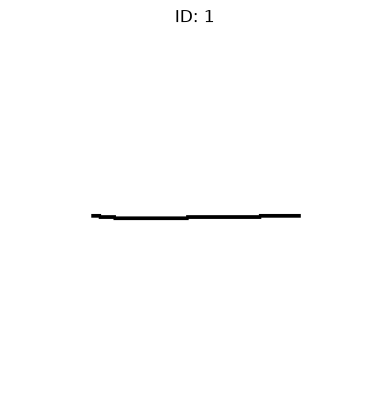

In [36]:
from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import random

QUICK_TEST = False
ROOT = Path.home() / "DIT5411" / "data" / "cleaned_data"

folders = sorted(
    p for p in ROOT.iterdir()
    if p.is_dir() and not p.name.startswith(".")
)
assert len(folders) == 13065, f"完整類別數唔啱：{len(folders)}"

selected = (
    sorted(random.Random(42).sample(folders, 20))
    if QUICK_TEST else folders
)
classes = [folder.name for folder in selected]
N = len(classes)

train_rows, test_rows = [], []
split_exceptions = []

for label, folder in enumerate(selected):
    files = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() == ".png"
    )
    total = len(files)
    assert total >= 2, f"{folder.name} 唔夠圖片分訓練同測試"

    if total > 40:
        n_train = 40
    else:
        n_train = (4 * total) // 5
        split_exceptions.append((folder.name, total, n_train, total - n_train))

    train_rows.extend((str(p), label) for p in files[:n_train])
    test_rows.extend((str(p), label) for p in files[n_train:])

train_counts = Counter(label for _, label in train_rows)
test_counts = Counter(label for _, label in test_rows)

assert len(train_counts) == len(test_counts) == N

if not QUICK_TEST:
    assert len(train_rows) + len(test_rows) == 684677
    assert len(split_exceptions) == 43

print("今次類別數：", N)
print("原始訓練圖片：", len(train_rows))
print("測試圖片：", len(test_rows))
print("例外類別數：", len(split_exceptions))
print("10020 分組（ID、總數、訓練、測試）：",
      next((row for row in split_exceptions if row[0] == "10020"), None))

path, label = train_rows[0]
with Image.open(path) as image:
    plt.imshow(image.convert("L"), cmap="gray", vmin=0, vmax=255)
plt.title(f"ID: {classes[label]}")
plt.axis("off")
plt.show()

今次類別數： 13065
每輪訓練樣本： 2613000
每輪批數： 81657
測試圖片： 162817


I0000 00:00:1795471949.080932    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 16004876536497580396
I0000 00:00:1795471949.081263    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 17299370704852790454
I0000 00:00:1795471949.081068   16244 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 600159979848102813
I0000 00:00:1795471949.081329   16244 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 9331274314832958771
I0000 00:00:1795471949.081343   16244 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 11475868004894444094
I0000 00:00:1795471949.081379   16244 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 15432963804901231462


第一批包含幾多類： 32


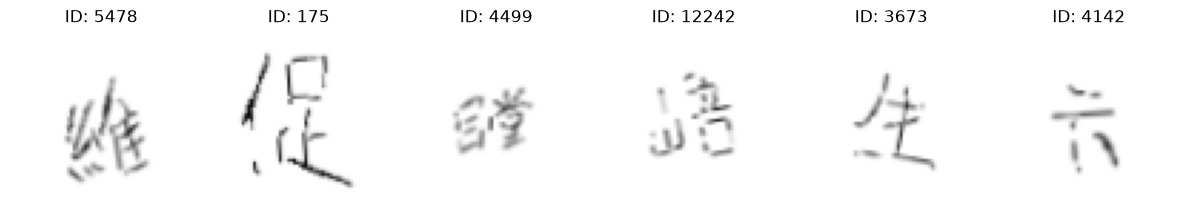

In [37]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from collections import defaultdict

keras.utils.set_random_seed(42)

IMG = 64
BATCH = 32
SAMPLES_PER_CLASS = 200

augment = keras.Sequential([
    layers.RandomRotation(
        0.035, fill_mode="constant", fill_value=1.0
    ),
    layers.RandomZoom(
        0.10, fill_mode="constant", fill_value=1.0
    ),
    layers.RandomTranslation(
        0.05, 0.05, fill_mode="constant", fill_value=1.0
    ),
])

def read_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=1)
    image = tf.image.resize(image, [IMG, IMG]) / 255.0
    return image, label

def make_dataset(rows, training=False):
    paths, labels = zip(*rows)
    path_tensor = tf.constant(paths)
    label_tensor = tf.constant(labels, dtype=tf.int32)

    if training:
        # 每個類別各自產生 200 個索引，只引用訓練原圖
        groups = defaultdict(list)
        for index, label in enumerate(labels):
            groups[label].append(index)

        rng = np.random.default_rng(42)
        all_indices = []

        for label in sorted(groups):
            original_indices = rng.permutation(groups[label])
            repeated = np.resize(original_indices, SAMPLES_PER_CLASS)
            all_indices.append(repeated)

        indices = np.concatenate(all_indices).astype(np.int32)

        # 全局 shuffle 嘅係整數索引，唔係已解碼圖片
        ds = tf.data.Dataset.from_tensor_slices(indices)
        ds = ds.shuffle(
            buffer_size=len(indices),
            seed=42,
            reshuffle_each_iteration=True,
        )
        ds = ds.map(
            lambda i: (
                tf.gather(path_tensor, i),
                tf.gather(label_tensor, i),
            ),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    else:
        ds = tf.data.Dataset.from_tensor_slices(
            (path_tensor, label_tensor)
        )

    ds = ds.map(
        read_image, num_parallel_calls=tf.data.AUTOTUNE
    ).batch(BATCH)

    if training:
        ds = ds.map(
            lambda x, y: (augment(x, training=True), y)
        )

    return ds.prefetch(1)

train_ds = make_dataset(train_rows, training=True)
test_ds = make_dataset(test_rows)
TOTAL_TRAIN_SAMPLES = N * SAMPLES_PER_CLASS

print("今次類別數：", N)
print("每輪訓練樣本：", TOTAL_TRAIN_SAMPLES)
print("每輪批數：", int(train_ds.cardinality().numpy()))
print("測試圖片：", len(test_rows))

images, labels = next(iter(train_ds))
print("第一批包含幾多類：", len(np.unique(labels.numpy())))

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, image, label in zip(axes, images[:6], labels[:6]):
    ax.imshow(image[:, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"ID: {classes[int(label)]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [39]:
# 前提：資料準備格同定義 build_spatial_model 嘅格已經跑過
assert not QUICK_TEST and N == 13065
assert IMG == 64 and BATCH == 32
assert tf.config.list_physical_devices("GPU"), "Notebook 未偵測到 GPU"

keras.utils.set_random_seed(42)

# 檢查全量訓練標籤係 0 至 13064，冇漏類
smoke_paths, smoke_labels = zip(*train_rows)
assert len(classes) == N
assert set(smoke_labels) == set(range(N)), "全量訓練標籤唔齊或編號有誤"

smoke_shift = layers.RandomTranslation(
    height_factor=1 / IMG,
    width_factor=1 / IMG,
    fill_mode="constant",
    fill_value=1.0,
    interpolation="nearest",
    seed=42,
)

def smoke_translate(x, y):
    return smoke_shift(x, training=True), y

# 先抽 256 張訓練原圖，再讀圖；唔建立完整重複抽樣流程
smoke_idx = np.random.default_rng(42).choice(
    len(train_rows), size=8 * BATCH, replace=False
)

smoke_ds = (
    tf.data.Dataset.from_tensor_slices((
        tf.constant([smoke_paths[i] for i in smoke_idx]),
        tf.constant([smoke_labels[i] for i in smoke_idx], dtype=tf.int32),
    ))
    .map(read_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH)
    .map(smoke_translate)
    .prefetch(1)
)

smoke_model = build_spatial_model("B_deeper", N)
assert smoke_model.output_shape[-1] == N

smoke_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

smoke_log = smoke_model.fit(
    smoke_ds,
    epochs=1,
    callbacks=[keras.callbacks.TerminateOnNaN()],
    verbose=2,
)

smoke_loss = float(smoke_log.history["loss"][-1])
assert np.isfinite(smoke_loss), "Loss 唔係有限數值"
assert int(smoke_model.optimizer.iterations.numpy()) == 8, "未跑足 8 批"

print(f"試跑成功：{N:,} 類輸出，完成 8 批，loss = {smoke_loss:.4f}")

/home/orinchan/DIT5411/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 - 1s - 129ms/step - accuracy: 0.0000e+00 - loss: 9.4786
試跑成功：13,065 類輸出，完成 8 批，loss = 9.4786


In [40]:
from collections import defaultdict
import numpy as np

assert not QUICK_TEST and N == 13065
assert len(classes) == N

rows_by_class = defaultdict(list)
for path, label in train_rows:
    rows_by_class[int(label)].append((path, int(label)))

assert set(rows_by_class) == set(range(N)), "訓練類別編號唔齊"

rng = np.random.default_rng(42)
full_fit_rows = []
full_val_rows = []

for label in range(N):
    rows = rows_by_class[label]
    order = rng.permutation(len(rows))
    n_val = (
        0 if len(rows) == 1
        else min(len(rows) - 1, max(1, round(0.10 * len(rows))))
    )

    full_val_rows.extend(rows[i] for i in order[:n_val])
    full_fit_rows.extend(rows[i] for i in order[n_val:])

fit_classes = {label for _, label in full_fit_rows}
val_classes = {label for _, label in full_val_rows}

assert len(full_fit_rows) + len(full_val_rows) == len(train_rows)
assert fit_classes == set(range(N)), "分割後有類別冇訓練原圖"
assert full_val_rows, "驗證集係空嘅"
assert {p for p, _ in full_fit_rows}.isdisjoint(
    p for p, _ in full_val_rows
), "同一圖片路徑同時出現喺訓練同驗證"

# training=False：只讀原圖，唔重複抽樣，唔做增強
full_val_ds = make_dataset(full_val_rows, training=False)

print(f"訓練原圖：{len(full_fit_rows):,} 張，{len(fit_classes):,} 類")
print(f"驗證原圖：{len(full_val_rows):,} 張，{len(val_classes):,} 類")
print(f"只留喺訓練集嘅類別：{N - len(val_classes):,} 類")

訓練原圖：469,673 張，13,065 類
驗證原圖：52,187 張，13,065 類
只留喺訓練集嘅類別：0 類


In [41]:
assert not QUICK_TEST and N == 13065
assert IMG == 64 and BATCH == 32 and SAMPLES_PER_CLASS == 200

full_paths, full_labels = zip(*full_fit_rows)
full_path_tensor = tf.constant(full_paths)
full_label_tensor = tf.constant(full_labels, dtype=tf.int32)

full_groups = defaultdict(list)
for i, label in enumerate(full_labels):
    full_groups[int(label)].append(i)

assert set(full_groups) == set(range(N))

full_rng = np.random.default_rng(42)
full_indices = np.concatenate([
    np.resize(full_rng.permutation(full_groups[label]), SAMPLES_PER_CLASS)
    for label in range(N)
]).astype(np.int32)

full_sample_count = N * SAMPLES_PER_CLASS
assert len(full_indices) == full_sample_count

def build_full_mild_ds(seed=42):
    shift = layers.RandomTranslation(
        height_factor=1 / IMG,
        width_factor=1 / IMG,
        fill_mode="constant",
        fill_value=1.0,
        interpolation="nearest",
        seed=seed,
    )

    def read_index(i):
        return read_image(
            tf.gather(full_path_tensor, i),
            tf.gather(full_label_tensor, i),
        )

    def translate_batch(x, y):
        return shift(x, training=True), y

    return (
        tf.data.Dataset.from_tensor_slices(full_indices)
        .shuffle(full_sample_count, seed=seed, reshuffle_each_iteration=True)
        .map(read_index, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH)
        .map(translate_batch)
        .prefetch(1)
    )

full_train_mild_ds = build_full_mild_ds()
full_batch_count = int(full_train_mild_ds.cardinality().numpy())
assert full_batch_count == (full_sample_count + BATCH - 1) // BATCH

check_x, check_y = next(iter(full_train_mild_ds.take(1)))
assert tuple(check_x.shape) == (BATCH, IMG, IMG, 1)
assert tuple(check_y.shape) == (BATCH,)
tf.debugging.assert_all_finite(check_x, "第一批圖片有非有限數值")
tf.debugging.assert_greater_equal(check_y, 0)
tf.debugging.assert_less(check_y, N)

print(f"每輪訓練樣本：{full_sample_count:,}")
print(f"每輪訓練批數：{full_batch_count:,}")
print(f"第一批檢查通過：圖片 {tuple(check_x.shape)}，標籤 {tuple(check_y.shape)}")

I0000 00:00:1795472118.063721    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 8288191575581778132
I0000 00:00:1795472118.063821    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 6781780331877172122
I0000 00:00:1795472118.063845    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 16643378810993301206
I0000 00:00:1795472118.063852    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 15936647098269695668


每輪訓練樣本：2,613,000
每輪訓練批數：81,657
第一批檢查通過：圖片 (32, 64, 64, 1)，標籤 (32,)


In [42]:
from pathlib import Path
from datetime import datetime
import time

assert not QUICK_TEST and N == 13065
assert full_batch_count == 81_657

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
FULL_MILD_OUT = Path.home() / "DIT5411" / "results" / f"full_mild_{run_id}"
FULL_MILD_OUT.mkdir(parents=True, exist_ok=False)

keras.utils.set_random_seed(42)
full_b_model = build_spatial_model("B_deeper", N)
full_b_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

best_path = FULL_MILD_OUT / "B_deeper_best.keras"
print("輸出資料夾：", FULL_MILD_OUT)
print(f"今次跑 1 輪，共 {full_batch_count:,} 個訓練批次。")

started = time.perf_counter()
full_b_history = full_b_model.fit(
    build_full_mild_ds(seed=42),
    validation_data=full_val_ds,
    epochs=1,
    callbacks=[
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.CSVLogger(str(FULL_MILD_OUT / "B_deeper_history.csv")),
        keras.callbacks.ModelCheckpoint(
            str(best_path),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
        ),
    ],
    verbose=1,
).history

assert int(full_b_model.optimizer.iterations.numpy()) == full_batch_count, "未跑完整輪"
assert best_path.is_file(), "未儲存驗證 checkpoint"
print(f"第 1 輪驗證準確率：{100 * full_b_history['val_accuracy'][-1]:.2f}%")
print(f"第 1 輪驗證 loss：{full_b_history['val_loss'][-1]:.4f}")
print(f"總用時（連驗證）：{(time.perf_counter() - started) / 60:.1f} 分鐘")

輸出資料夾： /home/orinchan/DIT5411/results/full_mild_20261124_061634_987113
今次跑 1 輪，共 81,657 個訓練批次。
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 1005s 12ms/step - accuracy: 6.3911e-05 - loss: 9.4942 - val_accuracy: 7.6647e-05 - val_loss: 9.4818
第 1 輪驗證準確率：0.01%
第 1 輪驗證 loss：9.4818
總用時（連驗證）：16.7 分鐘


In [43]:
probe_ids = np.random.default_rng(42).choice(
    len(full_fit_rows), size=128, replace=False
)
probe_rows = [full_fit_rows[i] for i in probe_ids]

feature_model = keras.Model(
    inputs=full_b_model.inputs,
    outputs=full_b_model.layers[-2].output,
)

feature_batches = []
predicted_ids = []

for x, _ in make_dataset(probe_rows, training=False):
    feature_batches.append(feature_model(x, training=False).numpy())
    predicted_ids.extend(
        tf.argmax(full_b_model(x, training=False), axis=1).numpy()
    )

features = np.concatenate(feature_batches, axis=0)
feature_spread = np.ptp(features, axis=0)

print(f"抽查原圖：{len(probe_rows)} 張，{len({y for _, y in probe_rows})} 類")
print(f"完全為零嘅特徵比例：{100 * np.mean(features == 0):.1f}%")
print(f"有隨圖片變化嘅特徵數：{np.count_nonzero(feature_spread > 1e-6)}/{features.shape[1]}")
print(f"模型實際預測咗幾多個唔同類別：{len(set(predicted_ids))}")

抽查原圖：128 張，127 類
完全為零嘅特徵比例：100.0%
有隨圖片變化嘅特徵數：0/64
模型實際預測咗幾多個唔同類別：1


In [44]:
SHORT_BATCHES = 1_000

# 固定用同一批未增強原圖量度特徵，唔用嚟更新權重
probe_x = tf.concat(
    [x for x, _ in make_dataset(probe_rows, training=False)],
    axis=0,
)

def feature_stats(model):
    extractor = keras.Model(model.inputs, model.layers[-2].output)
    f = extractor(probe_x, training=False).numpy()
    return (
        round(100 * float(np.mean(f == 0)), 2),
        int(np.count_nonzero(np.ptp(f, axis=0) > 1e-6)),
    )

short_rows = []

for lr in (0.001, 0.0001):
    keras.utils.set_random_seed(42)
    model = build_spatial_model("B_deeper", N)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    zero_before, varying_before = feature_stats(model)
    print(f"\nAdam LR = {lr:g}：試跑 {SHORT_BATCHES:,} 批")

    log = model.fit(
        build_full_mild_ds(seed=42).take(SHORT_BATCHES),
        epochs=1,
        callbacks=[keras.callbacks.TerminateOnNaN()],
        verbose=2,
    ).history

    steps = int(model.optimizer.iterations.numpy())
    loss = float(log["loss"][-1])
    assert steps == SHORT_BATCHES and np.isfinite(loss), (
        f"LR={lr:g} 未完成短跑或 loss 非有限：steps={steps}, loss={loss}"
    )

    zero_after, varying_after = feature_stats(model)
    short_rows.append({
        "learning_rate": lr,
        "train_loss": loss,
        "zero_pct_before": zero_before,
        "zero_pct_after": zero_after,
        "varying_before_of_64": varying_before,
        "varying_after_of_64": varying_after,
    })
    del model

print("\n===== 13,065 類：短程學習率對照 =====")
display(pd.DataFrame(short_rows).round(6))


Adam LR = 0.001：試跑 1,000 批
1000/1000 - 15s - 15ms/step - accuracy: 1.5625e-04 - loss: 9.4938

Adam LR = 0.0001：試跑 1,000 批
1000/1000 - 13s - 13ms/step - accuracy: 2.1875e-04 - loss: 9.4781

===== 13,065 類：短程學習率對照 =====


,learning_rate,train_loss,zero_pct_before,zero_pct_after,varying_before_of_64,varying_after_of_64
0,0.0010,9.493850,56.48,100.00,34,0
1,0.0001,9.478124,56.48,99.87,34,2


In [45]:
import numpy as np
import pandas as pd
from tensorflow import keras
from IPython.display import display

assert N == 13065 and not QUICK_TEST
STEPS = 1_000
SEED = 42
LR = 0.0001

# 用上一格已讀入嘅原圖，逐層檢查已訓練模型。
relu_layers = [
    layer for layer in full_b_model.layers
    if isinstance(layer, (keras.layers.Conv2D, keras.layers.Dense))
    and layer.get_config().get("activation") == "relu"
]
assert relu_layers, "搵唔到原版 B_deeper 嘅 ReLU 層"

trace_model = keras.Model(
    full_b_model.inputs, [layer.output for layer in relu_layers]
)

trace = []
for layer, values in zip(
    relu_layers, trace_model(probe_x[:32], training=False)
):
    a = values.numpy()
    trace.append({
        "layer": layer.name,
        "type": type(layer).__name__,
        "zero_pct": 100 * float(np.mean(a == 0)),
        "all_zero": bool(np.all(a == 0)),
    })

print("===== 舊模型：逐層檢查 =====")
display(pd.DataFrame(trace).round(2))

target = next((row["layer"] for row in trace if row["all_zero"]), None)
assert target is not None, "呢批圖未重現全零，先貼逐層表，唔好盲改"
print("今次只改呢一層：", target)

# 固定抽 1,024 張驗證原圖；唔用嚟更新權重。
val_ids = np.random.default_rng(SEED).choice(
    len(full_val_rows), size=1_024, replace=False
)
val_probe_ds = make_dataset(
    [full_val_rows[int(i)] for i in val_ids], training=False
)

keras.utils.set_random_seed(SEED)
template = build_spatial_model("B_deeper", N)
initial_weights = template.get_weights()

# Notebook 重建模型時層名可能會變，用層位置搵返同一層。
target_pos = full_b_model.layers.index(full_b_model.get_layer(target))
target_name = template.layers[target_pos].name

def clone_with_one_change(layer):
    config = layer.get_config()
    if layer.name == target_name:
        assert config["activation"] == "relu"
        config["activation"] = "leaky_relu"
    return layer.__class__.from_config(config)

comparison_rows = []

for variant in ("原版 ReLU", "單層 LeakyReLU"):
    keras.utils.set_random_seed(SEED)
    candidate = keras.models.clone_model(
        template,
        clone_function=(
            clone_with_one_change if variant == "單層 LeakyReLU" else None
        ),
    )
    candidate.set_weights(initial_weights)
    candidate.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    before = candidate.evaluate(val_probe_ds, verbose=0, return_dict=True)
    print(f"\n===== {variant}：試跑 {STEPS:,} 批 =====")

    log = candidate.fit(
        build_full_mild_ds(seed=SEED).take(STEPS),
        epochs=1,
        shuffle=False,
        callbacks=[keras.callbacks.TerminateOnNaN()],
        verbose=2,
    ).history

    assert int(candidate.optimizer.iterations.numpy()) == STEPS
    assert np.isfinite(log["loss"][-1])

    after = candidate.evaluate(val_probe_ds, verbose=0, return_dict=True)
    zero_pct, varying = feature_stats(candidate)
    comparison_rows.append({
        "model": variant,
        "train_loss": log["loss"][-1],
        "val_probe_loss_before": before["loss"],
        "val_probe_loss_after": after["loss"],
        "feature_zero_pct_after": zero_pct,
        "varying_features_of_64": varying,
    })

print("\n===== 單層激活函數對照 =====")
display(pd.DataFrame(comparison_rows).round(5))


===== 舊模型：逐層檢查 =====


,layer,type,zero_pct,all_zero
0,conv2d_16,Conv2D,67.80,False
1,conv2d_17,Conv2D,75.25,False
2,conv2d_18,Conv2D,76.86,False
3,conv2d_19,Conv2D,99.80,False
4,dense_8,Dense,100.00,True


今次只改呢一層： dense_8

===== 原版 ReLU：試跑 1,000 批 =====
1000/1000 - 13s - 13ms/step - accuracy: 3.1250e-05 - loss: 9.4781

===== 單層 LeakyReLU：試跑 1,000 批 =====
1000/1000 - 13s - 13ms/step - accuracy: 0.0000e+00 - loss: 9.4782

===== 單層激活函數對照 =====


,model,train_loss,val_probe_loss_before,val_probe_loss_after,feature_zero_pct_after,varying_features_of_64
0,原版 ReLU,9.47809,9.47779,9.47944,96.86,3
1,單層 LeakyReLU,9.47819,9.47774,9.47928,0.00,64


In [46]:
from collections import defaultdict
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

assert N == 13065 and not QUICK_TEST

def build_b_deeper_bn(num_classes, hidden=256):
    inputs = keras.Input((IMG, IMG, 1))
    x = inputs
    for filters in (16, 32):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(hidden, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="B_deeper_bn")

# 256 類 × 8 張訓練原圖；標籤保持原本 0–13064 編號
rng = np.random.default_rng(7)
by_class = defaultdict(list)
for path, label in full_fit_rows:
    by_class[int(label)].append(path)

mem_rows = []
for c in rng.choice(N, size=256, replace=False):
    paths = by_class[int(c)]
    for p in rng.choice(paths, size=min(8, len(paths)), replace=False):
        mem_rows.append((str(p), int(c)))

mem_x = tf.concat([x for x, _ in make_dataset(mem_rows, training=False)], 0)
mem_y = tf.constant([y for _, y in mem_rows], dtype=tf.int32)
print("記憶測試原圖：", len(mem_rows), "｜類別：", len(set(mem_y.numpy())))

builders = {
    "原版 B_deeper": lambda: build_spatial_model("B_deeper", N),
    "BN + Dense256": lambda: build_b_deeper_bn(N),
}

mem_results = []
for name, build in builders.items():
    keras.utils.set_random_seed(42)
    model = build()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )
    before = model.evaluate(mem_x, mem_y, batch_size=32, verbose=0, return_dict=True)
    print(f"\n===== {name}：記憶 40 輪 =====")
    model.fit(
        mem_x, mem_y,
        batch_size=32, epochs=40, shuffle=True,
        callbacks=[keras.callbacks.TerminateOnNaN()],
        verbose=0,
    )
    after = model.evaluate(mem_x, mem_y, batch_size=32, verbose=0, return_dict=True)
    zero_pct, varying = feature_stats(model)
    mem_results.append({
        "model": name,
        "loss_before": before["loss"],
        "loss_after": after["loss"],
        "memorize_acc_pct": 100 * after["accuracy"],
        "feature_zero_pct": zero_pct,
        "varying_of_features": varying,
    })
    del model

print("\n===== 13,065 類輸出：記憶測試（唔係正式成績） =====")
display(pd.DataFrame(mem_results).round(4))

記憶測試原圖： 2048 ｜類別： 256

===== 原版 B_deeper：記憶 40 輪 =====

===== BN + Dense256：記憶 40 輪 =====

===== 13,065 類輸出：記憶測試（唔係正式成績） =====


,model,loss_before,loss_after,memorize_acc_pct,feature_zero_pct,varying_of_features
0,原版 B_deeper,9.4776,0.2423,92.8711,86.23,15
1,BN + Dense256,9.4787,0.0013,100.0000,38.90,256


In [47]:
import math
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

assert N == 13065 and not QUICK_TEST
STEPS = 10_000
EVERY = 2_500
BASELINE = math.log(N)

val_px = tf.concat([x for x, _ in val_probe_ds], 0)
val_py = tf.concat([y for _, y in val_probe_ds], 0)

class ProbeTracker(keras.callbacks.Callback):
    def __init__(self, name):
        super().__init__()
        self.name, self.rows = name, []

    def on_train_batch_end(self, batch, logs=None):
        if (batch + 1) % EVERY:
            return
        probs = self.model.predict(val_px, batch_size=128, verbose=0)
        p_true = probs[np.arange(len(probs)), val_py.numpy()]
        zero_pct, varying = feature_stats(self.model)
        self.rows.append({
            "model": self.name,
            "batches": batch + 1,
            "train_loss": float(logs["loss"]),
            "val_probe_loss": float(-np.mean(np.log(p_true + 1e-12))),
            "val_probe_acc_pct": 100 * float(np.mean(probs.argmax(1) == val_py.numpy())),
            "feature_zero_pct": zero_pct,
            "varying_features": varying,
        })
        print(self.rows[-1])

builders = {
    "原版 B_deeper": lambda: build_spatial_model("B_deeper", N),
    "BN + Dense256": lambda: build_b_deeper_bn(N),
}

track_rows = []
for name, build in builders.items():
    print(f"\n===== {name}：全量短程 {STEPS:,} 批 =====")
    keras.utils.set_random_seed(42)
    model = build()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )
    tracker = ProbeTracker(name)
    model.fit(
        build_full_mild_ds(seed=42).take(STEPS),
        epochs=1,
        shuffle=False,
        callbacks=[keras.callbacks.TerminateOnNaN(), tracker],
        verbose=0,
    )
    track_rows.extend(tracker.rows)
    del model

print(f"\n均勻亂估 loss 參考值：{BASELINE:.4f}")
display(pd.DataFrame(track_rows).round(4))


===== 原版 B_deeper：全量短程 10,000 批 =====
{'model': '原版 B_deeper', 'batches': 2500, 'train_loss': 9.508936882019043, 'val_probe_loss': 9.527322769165039, 'val_probe_acc_pct': 0.0, 'feature_zero_pct': 100.0, 'varying_features': 0}
{'model': '原版 B_deeper', 'batches': 5000, 'train_loss': 9.512191772460938, 'val_probe_loss': 9.521247863769531, 'val_probe_acc_pct': 0.09765625, 'feature_zero_pct': 100.0, 'varying_features': 0}
{'model': '原版 B_deeper', 'batches': 7500, 'train_loss': 9.511338233947754, 'val_probe_loss': 9.51470947265625, 'val_probe_acc_pct': 0.09765625, 'feature_zero_pct': 100.0, 'varying_features': 0}
{'model': '原版 B_deeper', 'batches': 10000, 'train_loss': 9.510298728942871, 'val_probe_loss': 9.510818481445312, 'val_probe_acc_pct': 0.0, 'feature_zero_pct': 100.0, 'varying_features': 0}

===== BN + Dense256：全量短程 10,000 批 =====
{'model': 'BN + Dense256', 'batches': 2500, 'train_loss': 9.154932022094727, 'val_probe_loss': 8.979089736938477, 'val_probe_acc_pct': 0.1953125, 'feature

,model,batches,train_loss,val_probe_loss,val_probe_acc_pct,feature_zero_pct,varying_features
0,原版 B_deeper,2500,9.5089,9.5273,0.0000,100.00,0
1,原版 B_deeper,5000,9.5122,9.5212,0.0977,100.00,0
2,原版 B_deeper,7500,9.5113,9.5147,0.0977,100.00,0
3,原版 B_deeper,10000,9.5103,9.5108,0.0000,100.00,0
4,BN + Dense256,2500,9.1549,8.9791,0.1953,87.09,197
5,BN + Dense256,5000,8.3219,7.7850,0.9766,88.68,84
6,BN + Dense256,7500,7.3543,18.2500,0.1953,83.47,81
7,BN + Dense256,10000,6.5003,22.7668,0.1953,86.91,82


In [48]:
import math
import numpy as np
import tensorflow as tf
from tensorflow import keras

assert N == 13065 and not QUICK_TEST

keras.utils.set_random_seed(42)
bn_model = build_b_deeper_bn(N)
bn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

print("===== BN + Dense256：重新訓練 10,000 批 =====")
bn_log = bn_model.fit(
    build_full_mild_ds(seed=42).take(10_000),
    epochs=1,
    shuffle=False,
    callbacks=[keras.callbacks.TerminateOnNaN()],
    verbose=2,
).history

bn_path = FULL_MILD_OUT / "bn_dense256_10000_diag.keras"
assert not bn_path.exists(), "診斷檔已存在，唔覆蓋"
bn_model.save(str(bn_path))

vx = val_px.numpy()
vy = val_py.numpy()

def probe(model, training):
    losses, correct = [], 0
    for i in range(0, len(vx), 128):
        p = model(vx[i:i + 128], training=training).numpy()
        y = vy[i:i + 128]
        losses.append(-np.log(p[np.arange(len(y)), y] + 1e-12))
        correct += int(np.sum(p.argmax(1) == y))
    return float(np.concatenate(losses).mean()), 100 * correct / len(vy)

infer_loss, infer_acc = probe(bn_model, training=False)

# 批次統計模式會改 BN 移動平均，所以用載入嘅副本
batch_copy = keras.models.load_model(str(bn_path))
batch_loss, batch_acc = probe(batch_copy, training=True)
del batch_copy

print(f"\n均勻亂估 loss 參考值：{math.log(N):.4f}")
print(f"最後訓練 loss：{bn_log['loss'][-1]:.4f}")
print(f"推論模式（移動平均）：loss {infer_loss:.4f}｜準確率 {infer_acc:.2f}%")
print(f"批次統計模式：      loss {batch_loss:.4f}｜準確率 {batch_acc:.2f}%")
print("診斷檔：", bn_path)

===== BN + Dense256：重新訓練 10,000 批 =====
10000/10000 - 238s - 24ms/step - accuracy: 0.0896 - loss: 6.4608

均勻亂估 loss 參考值：9.4777
最後訓練 loss：6.4608
推論模式（移動平均）：loss 6.6078｜準確率 7.81%
批次統計模式：      loss 3.1227｜準確率 32.71%
診斷檔： /home/orinchan/DIT5411/results/full_mild_20261124_061634_987113/bn_dense256_10000_diag.keras


In [49]:
import numpy as np
from tensorflow import keras

CAL_BATCHES = 500

calib_model = keras.models.load_model(str(bn_path))
bn_layers = [l for l in calib_model.layers
             if isinstance(l, keras.layers.BatchNormalization)]
before_mean = bn_layers[-1].moving_mean.numpy().copy()

# 只用訓練原圖（冇增強），唔用驗證或測試圖
cal_ids = np.random.default_rng(99).choice(
    len(full_fit_rows), size=CAL_BATCHES * BATCH, replace=False
)
cal_ds = make_dataset([full_fit_rows[int(i)] for i in cal_ids], training=False)

# 唔計梯度、唔更新權重；training=True 只會更新 BN 移動平均
for x, _ in cal_ds:
    calib_model(x, training=True)

changed = not np.allclose(before_mean, bn_layers[-1].moving_mean.numpy())
assert changed, "BN 移動平均冇更新，校準無效"

cal_loss, cal_acc = probe(calib_model, training=False)

print("BN 移動平均已更新：", changed)
print(f"校準前推論模式：loss {infer_loss:.4f}｜準確率 {infer_acc:.2f}%")
print(f"校準後推論模式：loss {cal_loss:.4f}｜準確率 {cal_acc:.2f}%")
print(f"參考（唔合法）：批次統計 loss {batch_loss:.4f}｜準確率 {batch_acc:.2f}%")

BN 移動平均已更新： True
校準前推論模式：loss 6.6078｜準確率 7.81%
校準後推論模式：loss 3.0365｜準確率 33.98%
參考（唔合法）：批次統計 loss 3.1227｜準確率 32.71%


In [50]:
import math
import time
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

assert N == 13065 and not QUICK_TEST
CHECK_STEPS = 3_000

def conv_bn_relu(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

def build_bn_model(name, num_classes, hidden=256):
    inputs = keras.Input((IMG, IMG, 1))
    x = inputs
    for filters in (16, 32):
        x = conv_bn_relu(x, filters)
        if name == "B_deeper":
            x = conv_bn_relu(x, filters)
        elif name == "C_residual":
            branch = conv_bn_relu(x, filters)
            branch = layers.Conv2D(filters, 3, padding="same", use_bias=False)(branch)
            branch = layers.BatchNormalization()(branch)
            x = layers.ReLU()(layers.Add()([x, branch]))
        elif name != "A_spatial":
            raise ValueError(name)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(hidden, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"{name}_bn")

def calibrate_bn(model):
    # 只用訓練原圖更新 BN 移動平均，權重不變
    for x, _ in cal_ds:
        model(x, training=True)

check_rows = []
for name in ("A_spatial", "B_deeper", "C_residual"):
    print(f"\n===== {name}（BN 版）：{CHECK_STEPS:,} 批 =====")
    keras.utils.set_random_seed(42)
    model = build_bn_model(name, N)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )
    started = time.perf_counter()
    log = model.fit(
        build_full_mild_ds(seed=42).take(CHECK_STEPS),
        epochs=1, shuffle=False,
        callbacks=[keras.callbacks.TerminateOnNaN()],
        verbose=2,
    ).history
    sec_per_step = (time.perf_counter() - started) / CHECK_STEPS

    calibrate_bn(model)
    loss, acc = probe(model, training=False)
    zero_pct, varying = feature_stats(model)

    check_rows.append({
        "model": name,
        "parameters": model.count_params(),
        "train_loss": log["loss"][-1],
        "calibrated_val_loss": loss,
        "calibrated_val_acc_pct": acc,
        "varying_of_256": varying,
        "est_min_per_epoch": sec_per_step * full_batch_count / 60,
    })
    del model

print(f"\n均勻亂估 loss 參考值：{math.log(N):.4f}")
display(pd.DataFrame(check_rows).round(3))


===== A_spatial（BN 版）：3,000 批 =====
3000/3000 - 56s - 19ms/step - accuracy: 0.0024 - loss: 9.0069

===== B_deeper（BN 版）：3,000 批 =====
3000/3000 - 80s - 27ms/step - accuracy: 0.0019 - loss: 9.0388

===== C_residual（BN 版）：3,000 批 =====
3000/3000 - 104s - 35ms/step - accuracy: 0.0016 - loss: 9.0503

均勻亂估 loss 參考值：9.4777


,model,parameters,train_loss,calibrated_val_loss,calibrated_val_acc_pct,varying_of_256,est_min_per_epoch
0,A_spatial,5460825,9.007,8.147,0.586,96,25.638
1,B_deeper,5472537,9.039,8.198,0.977,83,36.302
2,C_residual,5484249,9.050,8.195,0.586,66,47.359


In [51]:
from pathlib import Path
import json
import time
import pandas as pd
from tensorflow import keras
from IPython.display import display

assert N == 13065 and not QUICK_TEST
EPOCHS = 2
NAMES_BN = ("A_spatial", "B_deeper", "C_residual")

OUT_BN = Path.home() / "DIT5411" / "results" / f"full_bn_e{EPOCHS}_b{BATCH}"
OUT_BN.mkdir(parents=True, exist_ok=True)

config = {
    "classes": N, "epochs": EPOCHS, "batch_size": BATCH, "image_size": IMG,
    "fit_images": len(full_fit_rows), "val_images": len(full_val_rows),
    "samples_per_class_per_epoch": SAMPLES_PER_CLASS,
    "augmentation": "RandomTranslation 1px, white fill, nearest",
    "bn_calibration_batches": 500, "optimizer": "Adam 0.001",
}
config_path = OUT_BN / "run_config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, "設定唔同，請換資料夾"
else:
    config_path.write_text(json.dumps(config, indent=2))
(OUT_BN / "labels.json").write_text(
    json.dumps(classes, ensure_ascii=False), encoding="utf-8"
)

def write_json(path, obj):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(json.dumps(obj, indent=2))
    tmp.replace(path)

for name in NAMES_BN:
    state_path = OUT_BN / f"{name}_state.json"
    last_path = OUT_BN / f"{name}_last.keras"
    best_path = OUT_BN / f"{name}_best.keras"
    state = (json.loads(state_path.read_text()) if state_path.exists()
             else {"epochs_done": 0, "best_val_acc": -1.0, "history": []})

    if state["epochs_done"] >= EPOCHS:
        print(f"跳過 {name}：已完成 {EPOCHS} 輪")
        continue

    keras.backend.clear_session()
    if state["epochs_done"] > 0:
        print(f"\n{name}：由第 {state['epochs_done'] + 1} 輪繼續")
        model = keras.models.load_model(str(last_path))
    else:
        keras.utils.set_random_seed(42)
        model = build_bn_model(name, N)
        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
            jit_compile=False,
        )

    for epoch in range(state["epochs_done"], EPOCHS):
        print(f"\n===== {name}：第 {epoch + 1}/{EPOCHS} 輪 =====")
        started = time.perf_counter()
        log = model.fit(
            build_full_mild_ds(seed=42 + epoch),
            epochs=1, shuffle=False,
            callbacks=[keras.callbacks.TerminateOnNaN()],
            verbose=1,
        ).history

        calibrate_bn(model)
        val = model.evaluate(full_val_ds, return_dict=True, verbose=1)
        minutes = (time.perf_counter() - started) / 60

        model.save(str(last_path))
        if val["accuracy"] > state["best_val_acc"]:
            model.save(str(best_path))
            state["best_val_acc"] = float(val["accuracy"])
            state["best_epoch"] = epoch + 1

        state["epochs_done"] = epoch + 1
        state["history"].append({
            "epoch": epoch + 1,
            "train_loss": float(log["loss"][-1]),
            "val_loss": float(val["loss"]),
            "val_acc_pct": 100 * float(val["accuracy"]),
            "minutes": round(minutes, 1),
        })
        write_json(state_path, state)
        print(f"{name} 第 {epoch + 1} 輪：驗證準確率 {100 * val['accuracy']:.2f}%"
              f"｜驗證 loss {val['loss']:.4f}｜{minutes:.1f} 分鐘")
    del model

summary = []
for name in NAMES_BN:
    s = json.loads((OUT_BN / f"{name}_state.json").read_text())
    summary.append({
        "model": name,
        "best_epoch": s["best_epoch"],
        "best_val_acc_pct": round(100 * s["best_val_acc"], 2),
        "last_val_acc_pct": round(s["history"][-1]["val_acc_pct"], 2),
        "last_val_loss": round(s["history"][-1]["val_loss"], 4),
    })

print("\n===== 全量驗證結果（未用測試集） =====")
display(pd.DataFrame(summary))
print("輸出資料夾：", OUT_BN)


===== A_spatial：第 1/2 輪 =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 1501s 18ms/step - accuracy: 0.6500 - loss: 1.7672
1631/1631 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8063 - loss: 0.7457
A_spatial 第 1 輪：驗證準確率 80.63%｜驗證 loss 0.7457｜25.4 分鐘

===== A_spatial：第 2/2 輪 =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 1487s 18ms/step - accuracy: 0.9122 - loss: 0.2979
1631/1631 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8359 - loss: 0.6852
A_spatial 第 2 輪：驗證準確率 83.59%｜驗證 loss 0.6852｜25.1 分鐘

===== B_deeper：第 1/2 輪 =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 1957s 24ms/step - accuracy: 0.7272 - loss: 1.3952
1631/1631 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8809 - loss: 0.4459
B_deeper 第 1 輪：驗證準確率 88.09%｜驗證 loss 0.4459｜33.1 分鐘

===== B_deeper：第 2/2 輪 =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 1954s 24ms/step - accuracy: 0.9540 - loss: 0.1475
1631/1631 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9033 - loss: 0.4071
B_deeper 第 2 輪：驗證準確率 90.33%｜驗證 loss 0.4071｜33.0 分鐘

===== C_residual：第 1/2 輪 ==

,model,best_epoch,best_val_acc_pct,last_val_acc_pct,last_val_loss
0,A_spatial,2,83.59,83.59,0.6852
1,B_deeper,2,90.33,90.33,0.4071
2,C_residual,2,92.09,92.09,0.3303


輸出資料夾： /home/orinchan/DIT5411/results/full_bn_e2_b32


In [38]:
print("QUICK_TEST =", repr(QUICK_TEST))
print("N =", N)
print("已載入嘅類別數 =", len(classes))

QUICK_TEST = False
N = 13065
已載入嘅類別數 = 13065


In [23]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

assert QUICK_TEST and N == 20, "請先用 20 類設定跑第四、五格"

# 只從原有訓練原圖分出驗證集，唔接觸 test_rows
groups = defaultdict(list)
for row in train_rows:
    groups[row[1]].append(row)

rng = np.random.default_rng(123)
fit_rows, val_rows = [], []

for label in sorted(groups):
    rows = groups[label]
    order = rng.permutation(len(rows))
    n_val = max(1, len(rows) // 5)
    val_rows.extend(rows[i] for i in order[:n_val])
    fit_rows.extend(rows[i] for i in order[n_val:])

assert not (
    {p for p, _ in fit_rows} & {p for p, _ in val_rows}
)

fit_ds = make_dataset(fit_rows, training=True)
val_ds = make_dataset(val_rows, training=False)

OUT_DIAG = Path.home() / "DIT5411" / "results" / "diagnostic_v2"
OUT_DIAG.mkdir(parents=True, exist_ok=True)

keras.backend.clear_session()
keras.utils.set_random_seed(42)

diagnostic_model = keras.Sequential([
    layers.Input(shape=(IMG, IMG, 1)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(96, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(N, activation="softmax"),
], name="diagnostic_spatial_cnn")

diagnostic_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

print("用作訓練嘅原圖：", len(fit_rows))
print("驗證原圖：", len(val_rows))
print("保留未評估嘅測試圖：", len(test_rows))

history = diagnostic_model.fit(
    fit_ds,
    validation_data=val_ds,
    epochs=15,
    shuffle=False,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            str(OUT_DIAG / "best.keras"),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            mode="max",
            patience=5,
            restore_best_weights=True,
        ),
        keras.callbacks.CSVLogger(str(OUT_DIAG / "history.csv")),
    ],
    verbose=1,
)

history_table = pd.DataFrame(history.history)
history_table.index = np.arange(1, len(history_table) + 1)
history_table.index.name = "epoch"

print("\n===== 學習檢查結果 =====")
display(history_table.round(4))
print(f"最高驗證準確率：{100 * max(history.history['val_accuracy']):.2f}%")
print("測試集未參與今次訓練或選模型。")

用作訓練嘅原圖： 640
驗證原圖： 160
保留未評估嘅測試圖： 268
Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0525 - loss: 2.9997 - val_accuracy: 0.0500 - val_loss: 2.9957
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0448 - loss: 2.9961 - val_accuracy: 0.0500 - val_loss: 2.9957
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0498 - loss: 2.9961 - val_accuracy: 0.0500 - val_loss: 2.9957
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.0468 - loss: 2.9962 - val_accuracy: 0.0500 - val_loss: 2.9957
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.0515 - loss: 2.9962 - val_accuracy: 0.0500 - val_loss: 2.9957
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.0415 - loss: 2.9962 - val_accuracy: 0.0500 - val_loss: 2.9957

===== 學習檢查結果 =====


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.0525,2.9997,0.05,2.9957
2,0.0448,2.9961,0.05,2.9957
3,0.0498,2.9961,0.05,2.9957
4,0.0468,2.9962,0.05,2.9957
5,0.0515,2.9962,0.05,2.9957
6,0.0415,2.9962,0.05,2.9957


最高驗證準確率：5.00%
測試集未參與今次訓練或選模型。


===== 1. 原始圖 vs 預處理後 =====

類別 ID：10366
PIL 原圖： mode = RGB dtype = uint8 shape = (300, 300, 3) min/max = (np.uint8(0), np.uint8(255))
TF 原圖： dtype = uint8 min/max = (0, 255)
預處理後： min/max = (0.0, 1.0) mean/std = (0.9708456993103027, 0.15813206136226654) label = 0

類別 ID：1850
PIL 原圖： mode = RGB dtype = uint8 shape = (300, 300, 3) min/max = (np.uint8(0), np.uint8(255))
TF 原圖： dtype = uint8 min/max = (0, 255)
預處理後： min/max = (0.0, 1.0) mean/std = (0.9798030853271484, 0.13042239844799042) label = 10

類別 ID：9174
PIL 原圖： mode = RGB dtype = uint8 shape = (300, 300, 3) min/max = (np.uint8(0), np.uint8(255))
TF 原圖： dtype = uint8 min/max = (0, 255)
預處理後： min/max = (0.0, 1.0) mean/std = (0.9654288291931152, 0.1687561571598053) label = 19


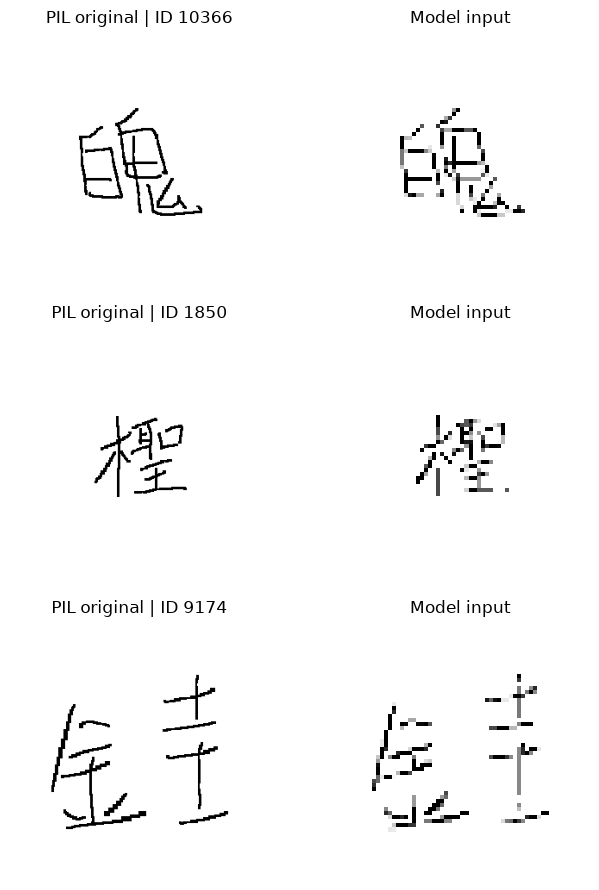


===== 2. 增強後實際批次 =====
圖片形狀： (32, 64, 64, 1)
資料型別： float32
全部數值有限： True
批次 min/max： 0.0 1.0
批次 mean/std： 0.9695188999176025 0.10515180230140686
每張圖 std（頭 8 張）： [0.109536 0.121622 0.116746 0.094326 0.12372  0.117574 0.100292 0.089695]
標籤範圍： 1 19
模型輸出形狀： (None, 20)

===== 3. 模型預測係咪接近均勻 =====


I0000 00:00:1795468505.253220    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7917521506569949518
I0000 00:00:1795468505.253488    1568 local_rendezvous.cc:486] Local rendezvous send item cancelled. Key hash: 1477561476567193416
W0000 00:00:1795468505.253518    1568 local_rendezvous.cc:461] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node sequential/random_translation/ReadVariableOp/_8}}]]
	 [[sequential/random_translation/Add_1/_24]] [type.googleapis.com/tensorflow.DerivedStatus='']
=== Source Location Trace: ===
tensorflow/core/framework/local_rendezvous.cc:339
tensorflow/core/common_runtime/executor.cc:1156
tensorflow/core/common_runtime/executor.cc:1156

I0000 00:00:1795468505.253593    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 3786148050780664453
I0000 00:00:1795468505.253601    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 4281557139167634284

每張圖最高預測概率（頭 8 張）： [0.050795 0.050766 0.050786 0.050783 0.050769 0.050773 0.050776 0.050793]
平均最高預測概率： 0.05078005790710449


In [24]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

print("===== 1. 原始圖 vs 預處理後 =====")

check_indices = [0, len(train_rows) // 2, len(train_rows) - 1]
fig, axes = plt.subplots(3, 2, figsize=(7, 9))

for row, index in enumerate(check_indices):
    path, label = train_rows[index]

    with Image.open(path) as im:
        pil_mode = im.mode
        raw_pil = np.array(im)
        gray_pil = np.array(im.convert("L"))

    raw_tf = tf.io.decode_png(tf.io.read_file(path), channels=1)
    processed, output_label = read_image(
        tf.constant(path), tf.constant(label, dtype=tf.int32)
    )
    x = processed.numpy()

    print(f"\n類別 ID：{classes[label]}")
    print(
        "PIL 原圖：",
        "mode =", pil_mode,
        "dtype =", raw_pil.dtype,
        "shape =", raw_pil.shape,
        "min/max =", (raw_pil.min(), raw_pil.max()),
    )
    print(
        "TF 原圖：",
        "dtype =", raw_tf.dtype.name,
        "min/max =", (
            int(tf.reduce_min(raw_tf)),
            int(tf.reduce_max(raw_tf)),
        ),
    )
    print(
        "預處理後：",
        "min/max =", (float(x.min()), float(x.max())),
        "mean/std =", (float(x.mean()), float(x.std())),
        "label =", int(output_label),
    )

    axes[row, 0].imshow(gray_pil, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"PIL original | ID {classes[label]}")
    axes[row, 1].imshow(x[:, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Model input")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

print("\n===== 2. 增強後實際批次 =====")
batch_x, batch_y = next(iter(fit_ds))
a = batch_x.numpy()

print("圖片形狀：", a.shape)
print("資料型別：", a.dtype)
print("全部數值有限：", bool(np.isfinite(a).all()))
print("批次 min/max：", float(a.min()), float(a.max()))
print("批次 mean/std：", float(a.mean()), float(a.std()))
print("每張圖 std（頭 8 張）：",
      np.round(a.std(axis=(1, 2, 3))[:8], 6))
print("標籤範圍：", int(tf.reduce_min(batch_y)),
      int(tf.reduce_max(batch_y)))
print("模型輸出形狀：", diagnostic_model.output_shape)

print("\n===== 3. 模型預測係咪接近均勻 =====")
p = diagnostic_model(batch_x, training=False).numpy()
print("每張圖最高預測概率（頭 8 張）：",
      np.round(p.max(axis=1)[:8], 6))
print("平均最高預測概率：", float(p.max(axis=1).mean()))

In [25]:
from collections import defaultdict

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

assert QUICK_TEST and N == 20, "請先保持第四格 QUICK_TEST = True"

# 固定抽樣：兩個版本用完全相同嘅原圖同標籤
groups = defaultdict(list)
for path, label in train_rows:
    groups[label].append(path)

rng = np.random.default_rng(123)
small_rows = []

for label in sorted(groups):
    paths = groups[label]
    assert len(paths) >= 4, f"類別 {label} 唔夠 4 張訓練原圖"
    for index in rng.choice(len(paths), size=4, replace=False):
        small_rows.append((paths[int(index)], label))

assert len(small_rows) == 80
y_small = np.array([label for _, label in small_rows], dtype=np.int32)

def load_small_images(antialias):
    output = []
    for path, _ in small_rows:
        raw = tf.io.decode_png(tf.io.read_file(path), channels=1)
        resized = tf.image.resize(
            raw, (64, 64), method="bilinear", antialias=antialias
        )
        output.append((resized / 255.0).numpy())
    return np.stack(output)

def make_memory_model():
    return keras.Sequential([
        layers.Input((64, 64, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(N, activation="softmax"),
    ])

print("記憶測試原圖：", len(y_small))
print("每類張數：", np.bincount(y_small, minlength=N).tolist())

for antialias in (False, True):
    keras.backend.clear_session()
    keras.utils.set_random_seed(123)

    x_small = load_small_images(antialias)
    model = make_memory_model()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    before = model.evaluate(x_small, y_small, verbose=0, return_dict=True)

    model.fit(
        x_small, y_small,
        batch_size=16,
        epochs=30,
        shuffle=True,
        verbose=0,
    )

    after = model.evaluate(x_small, y_small, verbose=0, return_dict=True)
    print(
        f"antialias={antialias} | "
        f"記憶準確率 {100 * before['accuracy']:.1f}%"
        f" → {100 * after['accuracy']:.1f}% | "
        f"loss {before['loss']:.4f} → {after['loss']:.4f}"
    )

記憶測試原圖： 80
每類張數： [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
antialias=False | 記憶準確率 5.0% → 98.8% | loss 3.0138 → 0.2606
antialias=True | 記憶準確率 5.0% → 88.7% | loss 3.0115 → 0.6493


In [26]:
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

assert QUICK_TEST and N == 20, "請保持 20 類設定"
assert not ({p for p, _ in fit_rows} & {p for p, _ in val_rows})
assert len(Counter(label for _, label in val_rows)) == N

SEED = 123
EPOCHS_COMPARE = 15
BATCH_COMPARE = 32

def load_rows(rows):
    images, labels = [], []
    for path, label in rows:
        raw = tf.io.decode_png(tf.io.read_file(path), channels=1)
        img = tf.image.resize(
            raw, (64, 64), method="bilinear", antialias=False
        ) / 255.0
        images.append(img.numpy())
        labels.append(label)
    return np.stack(images), np.asarray(labels, dtype=np.int32)

x_fit, y_fit = load_rows(fit_rows)
x_val, y_val = load_rows(val_rows)

# 兩組每輪都用相同嘅 4,000 個索引：每類 200 個。
# 冇增強組重複原圖；有增強組對同一批原圖做隨機變形。
groups = defaultdict(list)
for index, label in enumerate(y_fit):
    groups[int(label)].append(index)

rng = np.random.default_rng(SEED)
indices = np.concatenate([
    np.resize(rng.permutation(groups[label]), 200)
    for label in range(N)
]).astype(np.int32)

fit_images = tf.constant(x_fit)
fit_labels = tf.constant(y_fit)
augmentation_config = augment.get_config()

print("訓練原圖：", len(y_fit))
print("驗證原圖：", len(y_val))
print("每組每輪樣本：", len(indices))

comparison = []

for use_aug in (False, True):
    name = "有增強" if use_aug else "冇增強"
    print(f"\n===== {name} =====")

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model = make_memory_model()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    ds = tf.data.Dataset.from_tensor_slices(indices)
    ds = ds.shuffle(
        len(indices), seed=SEED, reshuffle_each_iteration=True
    ).batch(BATCH_COMPARE)

    ds = ds.map(
        lambda i: (tf.gather(fit_images, i), tf.gather(fit_labels, i))
    )

    if use_aug:
        comparison_augment = keras.Sequential.from_config(augmentation_config)
        ds = ds.map(
            lambda x, y: (comparison_augment(x, training=True), y)
        )

    history = model.fit(
        ds.prefetch(1),
        validation_data=(x_val, y_val),
        validation_batch_size=BATCH_COMPARE,
        epochs=EPOCHS_COMPARE,
        shuffle=False,
        verbose=2,
    ).history

    best = int(np.argmax(history["val_accuracy"]))
    comparison.append({
        "設定": name,
        "最佳驗證輪次": best + 1,
        "最高驗證準確率 (%)": round(100 * history["val_accuracy"][best], 2),
        "最後一輪訓練準確率 (%)": round(100 * history["accuracy"][-1], 2),
        "最後一輪驗證準確率 (%)": round(100 * history["val_accuracy"][-1], 2),
    })

print("\n===== 20 類驗證比較（唔係正式測試成績） =====")
display(pd.DataFrame(comparison))

訓練原圖： 640
驗證原圖： 160
每組每輪樣本： 4000

===== 冇增強 =====
Epoch 1/15
125/125 - 2s - 13ms/step - accuracy: 0.2260 - loss: 2.5564 - val_accuracy: 0.5000 - val_loss: 1.6392
Epoch 2/15
125/125 - 1s - 7ms/step - accuracy: 0.8095 - loss: 0.6876 - val_accuracy: 0.6875 - val_loss: 1.1647
Epoch 3/15
125/125 - 1s - 7ms/step - accuracy: 0.9545 - loss: 0.1937 - val_accuracy: 0.7375 - val_loss: 1.0815
Epoch 4/15
125/125 - 1s - 7ms/step - accuracy: 0.9940 - loss: 0.0594 - val_accuracy: 0.7625 - val_loss: 1.0937
Epoch 5/15
125/125 - 1s - 6ms/step - accuracy: 0.9992 - loss: 0.0191 - val_accuracy: 0.7750 - val_loss: 1.1314
Epoch 6/15
125/125 - 1s - 7ms/step - accuracy: 1.0000 - loss: 0.0083 - val_accuracy: 0.7937 - val_loss: 1.1829
Epoch 7/15
125/125 - 1s - 6ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 0.7812 - val_loss: 1.2372
Epoch 8/15
125/125 - 1s - 6ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.7688 - val_loss: 1.2773
Epoch 9/15
125/125 - 1s - 6ms/step - accuracy: 1.0000 - loss:

,設定,最佳驗證輪次,最高驗證準確率 (%),最後一輪訓練準確率 (%),最後一輪驗證準確率 (%)
0,冇增強,6,79.37,100.00,78.12
1,有增強,15,84.38,89.25,84.38


In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

PILOT_N = 200
PILOT_EPOCHS = 5
SEED = 123
assert IMG == 64, "請先用新版第五格嘅 64×64 設定"

root = Path.home() / "DIT5411" / "data" / "cleaned_data"
folders = sorted(
    p for p in root.iterdir()
    if p.is_dir() and not p.name.startswith(".")
)

rng = np.random.default_rng(SEED)
selected = [folders[i] for i in sorted(
    rng.choice(len(folders), size=PILOT_N, replace=False)
)]

pilot_fit, pilot_val = [], []
for label, folder in enumerate(selected):
    files = sorted(p for p in folder.glob("*.png") if p.is_file())

    # 沿用正式分組規則；只從訓練部分抽驗證圖。
    n_original_train = 40 if len(files) > 40 else 4 * len(files) // 5
    assert n_original_train >= 2, f"{folder.name} 唔夠原圖"
    eligible = files[:n_original_train]
    order = rng.permutation(n_original_train)
    n_val = max(1, n_original_train // 5)

    pilot_val.extend((str(eligible[i]), label) for i in order[:n_val])
    pilot_fit.extend((str(eligible[i]), label) for i in order[n_val:])

assert not ({p for p, _ in pilot_fit} & {p for p, _ in pilot_val})

def build_pilot_model(name):
    inputs = keras.Input(shape=(IMG, IMG, 1))
    x = inputs

    if name == "A_simple":
        for filters in (24, 48):
            x = layers.Conv2D(
                filters, 3, padding="same", activation="relu"
            )(x)
            x = layers.MaxPooling2D()(x)
        x = layers.AveragePooling2D(pool_size=2)(x)

    elif name == "B_deep":
        for filters in (24, 48, 96):
            for _ in range(2):
                x = layers.Conv2D(
                    filters, 3, padding="same", use_bias=False
                )(x)
                x = layers.BatchNormalization()(x)
                x = layers.ReLU()(x)
            x = layers.MaxPooling2D()(x)

    elif name == "C_residual":
        for filters in (24, 48, 96):
            skip = layers.Conv2D(
                filters, 1, strides=2, padding="same"
            )(x)
            x = layers.Conv2D(
                filters, 3, strides=2, padding="same", activation="relu"
            )(x)
            x = layers.Conv2D(filters, 3, padding="same")(x)
            x = layers.ReLU()(layers.Add()([x, skip]))

    else:
        raise ValueError(name)

    # 三款都保留 8×8 嘅空間位置，而唔係平均成一點。
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(PILOT_N, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

print("試驗類別數：", PILOT_N)
print("訓練原圖：", len(pilot_fit))
print("驗證原圖：", len(pilot_val))
print("每款每輪增強樣本：", PILOT_N * SAMPLES_PER_CLASS)

summary_rows = []

for name in ("A_simple", "B_deep", "C_residual"):
    print(f"\n===== 200 類驗證：{name} =====")
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    pilot_train_ds = make_dataset(pilot_fit, training=True)
    pilot_val_ds = make_dataset(pilot_val, training=False)

    model = build_pilot_model(name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    log = model.fit(
        pilot_train_ds,
        validation_data=pilot_val_ds,
        epochs=PILOT_EPOCHS,
        shuffle=False,
        verbose=2,
    ).history

    summary_rows.append({
        "model": name,
        "epoch_1_val_pct": 100 * log["val_accuracy"][0],
        "epoch_5_val_pct": 100 * log["val_accuracy"][-1],
        "best_val_pct": 100 * max(log["val_accuracy"]),
        "epoch_5_train_pct": 100 * log["accuracy"][-1],
    })

print("\n===== 200 類驗證結果（唔係正式測試成績） =====")
display(pd.DataFrame(summary_rows).round(2))

試驗類別數： 200
訓練原圖： 6400
驗證原圖： 1600
每款每輪增強樣本： 40000

===== 200 類驗證：A_simple =====
Epoch 1/5
1250/1250 - 13s - 10ms/step - accuracy: 0.0034 - loss: 5.2999 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 2/5
1250/1250 - 13s - 10ms/step - accuracy: 0.0032 - loss: 5.2995 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 3/5
1250/1250 - 12s - 10ms/step - accuracy: 0.0037 - loss: 5.2995 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 4/5
1250/1250 - 12s - 10ms/step - accuracy: 0.0043 - loss: 5.2995 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 5/5
1250/1250 - 13s - 10ms/step - accuracy: 0.0038 - loss: 5.2994 - val_accuracy: 0.0050 - val_loss: 5.2983

===== 200 類驗證：B_deep =====
Epoch 1/5
1250/1250 - 37s - 30ms/step - accuracy: 0.0068 - loss: 5.1698 - val_accuracy: 0.0081 - val_loss: 5.0410
Epoch 2/5
1250/1250 - 35s - 28ms/step - accuracy: 0.0086 - loss: 5.0399 - val_accuracy: 0.0131 - val_loss: 4.9376
Epoch 3/5
1250/1250 - 36s - 29ms/step - accuracy: 0.0084 - loss: 5.0078 - val_accuracy: 0.0069 

,model,epoch_1_val_pct,epoch_5_val_pct,best_val_pct,epoch_5_train_pct
0,A_simple,0.50,0.50,0.50,0.38
1,B_deep,0.81,1.25,1.31,0.96
2,C_residual,0.50,0.50,0.50,0.39


In [28]:
import tensorflow as tf
from tensorflow import keras

assert PILOT_N == 200, "請先跑 200 類驗證嗰格"
assert len({label for _, label in pilot_fit}) == PILOT_N
assert len({label for _, label in pilot_val}) == PILOT_N

keras.backend.clear_session()
keras.utils.set_random_seed(123)

def invert_batch(images, labels):
    return 1.0 - images, labels

# 沿用同一批資料、同一個分組同原本嘅增強設定
invert_train_ds = make_dataset(pilot_fit, training=True).map(invert_batch)
invert_val_ds = make_dataset(pilot_val, training=False).map(invert_batch)

probe_model = build_pilot_model("B_deep")
probe_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

print("===== B_deep：200 類反色試驗 =====")
invert_log = probe_model.fit(
    invert_train_ds,
    validation_data=invert_val_ds,
    epochs=5,
    shuffle=False,
    verbose=2,
).history

print("\n===== 同原本 B_deep 比較 =====")
print("原本白底：最高驗證 1.31%，第 5 輪驗證 1.25%")
print(f"反色黑底：最高驗證 {100 * max(invert_log['val_accuracy']):.2f}%")
print(f"反色黑底：第 5 輪驗證 {100 * invert_log['val_accuracy'][-1]:.2f}%")
print(f"反色黑底：第 5 輪訓練 {100 * invert_log['accuracy'][-1]:.2f}%")

===== B_deep：200 類反色試驗 =====
Epoch 1/5
1250/1250 - 39s - 31ms/step - accuracy: 0.0071 - loss: 5.1582 - val_accuracy: 0.0100 - val_loss: 5.2253
Epoch 2/5
1250/1250 - 38s - 31ms/step - accuracy: 0.0088 - loss: 5.0251 - val_accuracy: 0.0081 - val_loss: 5.4917
Epoch 3/5
1250/1250 - 39s - 31ms/step - accuracy: 0.0099 - loss: 4.9843 - val_accuracy: 0.0150 - val_loss: 4.8536
Epoch 4/5
1250/1250 - 40s - 32ms/step - accuracy: 0.0103 - loss: 4.9554 - val_accuracy: 0.0169 - val_loss: 4.8428
Epoch 5/5
1250/1250 - 40s - 32ms/step - accuracy: 0.0117 - loss: 4.9337 - val_accuracy: 0.0150 - val_loss: 4.8053

===== 同原本 B_deep 比較 =====
原本白底：最高驗證 1.31%，第 5 輪驗證 1.25%
反色黑底：最高驗證 1.69%
反色黑底：第 5 輪驗證 1.50%
反色黑底：第 5 輪訓練 1.17%


In [29]:
from collections import defaultdict

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

assert PILOT_N == 200, "請先跑過 200 類分組嗰格"
assert len({label for _, label in pilot_fit}) == PILOT_N
assert len({label for _, label in pilot_val}) == PILOT_N
assert not ({p for p, _ in pilot_fit} & {p for p, _ in pilot_val})

SEED_200 = 123
BATCH_200 = 32
EPOCHS_200 = 5

keras.backend.clear_session()
keras.utils.set_random_seed(SEED_200)

# load_rows 係之前「有增強 vs 冇增強」嗰格嘅函數：
# 64×64、白底、antialias=False。
x_fit_200, y_fit_200 = load_rows(pilot_fit)
x_val_200, y_val_200 = load_rows(pilot_val)

groups_200 = defaultdict(list)
for index, label in enumerate(y_fit_200):
    groups_200[int(label)].append(index)

rng_200 = np.random.default_rng(SEED_200)
indices_200 = np.concatenate([
    np.resize(rng_200.permutation(groups_200[label]), 200)
    for label in range(PILOT_N)
]).astype(np.int32)
assert len(indices_200) == 40_000

images_200 = tf.constant(x_fit_200)
labels_200 = tf.constant(y_fit_200)
aug_200 = keras.Sequential.from_config(augment.get_config())

def get_augmented_batch_200(indices):
    images = tf.gather(images_200, indices)
    labels = tf.gather(labels_200, indices)
    return aug_200(images, training=True), labels

learn_ds_200 = (
    tf.data.Dataset.from_tensor_slices(indices_200)
    .shuffle(len(indices_200), seed=SEED_200, reshuffle_each_iteration=True)
    .batch(BATCH_200)
    .map(get_augmented_batch_200)
    .prefetch(1)
)

learn_model_200 = keras.Sequential([
    layers.Input((64, 64, 1)),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(PILOT_N, activation="softmax"),
], name="spatial_cnn_200")

learn_model_200.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

print("訓練原圖：", len(y_fit_200))
print("驗證原圖：", len(y_val_200))
print("每輪增強樣本：", len(indices_200))

learn_log_200 = learn_model_200.fit(
    learn_ds_200,
    validation_data=(x_val_200, y_val_200),
    validation_batch_size=BATCH_200,
    epochs=EPOCHS_200,
    shuffle=False,
    verbose=2,
).history

print("\n===== 200 類空間 CNN 驗證 =====")
print(f"最高驗證準確率：{100 * max(learn_log_200['val_accuracy']):.2f}%")
print(f"第 5 輪驗證準確率：{100 * learn_log_200['val_accuracy'][-1]:.2f}%")
print(f"第 5 輪訓練準確率：{100 * learn_log_200['accuracy'][-1]:.2f}%")

訓練原圖： 6400
驗證原圖： 1600
每輪增強樣本： 40000
Epoch 1/5
1250/1250 - 10s - 8ms/step - accuracy: 0.0037 - loss: 5.3000 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 2/5
1250/1250 - 8s - 7ms/step - accuracy: 0.0039 - loss: 5.2995 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 3/5
1250/1250 - 9s - 7ms/step - accuracy: 0.0038 - loss: 5.2996 - val_accuracy: 0.0063 - val_loss: 5.2982
Epoch 4/5
1250/1250 - 9s - 7ms/step - accuracy: 0.0039 - loss: 5.2995 - val_accuracy: 0.0050 - val_loss: 5.2983
Epoch 5/5
1250/1250 - 9s - 7ms/step - accuracy: 0.0054 - loss: 5.2855 - val_accuracy: 0.0312 - val_loss: 5.1041

===== 200 類空間 CNN 驗證 =====
最高驗證準確率：3.12%
第 5 輪驗證準確率：3.12%
第 5 輪訓練準確率：0.54%


In [30]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

assert PILOT_N == 200
assert len(indices_200) == 40_000
assert learn_model_200.output_shape[-1] == PILOT_N

# 用原圖重新評估已訓練好嘅「有增強」模型
aug_clean = learn_model_200.evaluate(
    x_fit_200, y_fit_200,
    batch_size=BATCH_200, verbose=0, return_dict=True,
)

# 同一個模型架構，由頭訓練；唔沿用有增強版嘅權重
keras.utils.set_random_seed(SEED_200)
noaug_model_200 = keras.models.clone_model(learn_model_200)
noaug_model_200.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

def get_clean_batch_200(indices):
    return tf.gather(images_200, indices), tf.gather(labels_200, indices)

# 同樣每類 200 個索引、每輪 40,000 個樣本；
# 今次只係重複原圖，唔做旋轉、縮放或平移。
noaug_ds_200 = (
    tf.data.Dataset.from_tensor_slices(indices_200)
    .shuffle(len(indices_200), seed=SEED_200, reshuffle_each_iteration=True)
    .batch(BATCH_200)
    .map(get_clean_batch_200)
    .prefetch(1)
)

noaug_log_200 = noaug_model_200.fit(
    noaug_ds_200,
    validation_data=(x_val_200, y_val_200),
    validation_batch_size=BATCH_200,
    epochs=EPOCHS_200,
    shuffle=False,
    verbose=2,
).history

noaug_clean = noaug_model_200.evaluate(
    x_fit_200, y_fit_200,
    batch_size=BATCH_200, verbose=0, return_dict=True,
)

def result_row(name, log, clean_scores):
    return {
        "設定": name,
        "最高驗證準確率 (%)": 100 * max(log["val_accuracy"]),
        "第 5 輪驗證準確率 (%)": 100 * log["val_accuracy"][-1],
        "輪末原圖訓練準確率 (%)": 100 * clean_scores["accuracy"],
        "第 5 輪驗證 loss": log["val_loss"][-1],
    }

print("\n===== 200 類增強對照（唔係正式測試成績） =====")
display(pd.DataFrame([
    result_row("有增強", learn_log_200, aug_clean),
    result_row("冇增強", noaug_log_200, noaug_clean),
]).round(2))

Epoch 1/5
1250/1250 - 8s - 6ms/step - accuracy: 0.2700 - loss: 3.2476 - val_accuracy: 0.4538 - val_loss: 2.1722
Epoch 2/5
1250/1250 - 7s - 6ms/step - accuracy: 0.7261 - loss: 0.9809 - val_accuracy: 0.5756 - val_loss: 1.8040
Epoch 3/5
1250/1250 - 7s - 6ms/step - accuracy: 0.8741 - loss: 0.4360 - val_accuracy: 0.6206 - val_loss: 1.8866
Epoch 4/5
1250/1250 - 7s - 6ms/step - accuracy: 0.9374 - loss: 0.2264 - val_accuracy: 0.6444 - val_loss: 2.0096
Epoch 5/5
1250/1250 - 7s - 5ms/step - accuracy: 0.9643 - loss: 0.1281 - val_accuracy: 0.6425 - val_loss: 2.3029

===== 200 類增強對照（唔係正式測試成績） =====


,設定,最高驗證準確率 (%),第 5 輪驗證準確率 (%),輪末原圖訓練準確率 (%),第 5 輪驗證 loss
0,有增強,3.12,3.12,4.44,5.1
1,冇增強,64.44,64.25,97.33,2.3


In [31]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

assert PILOT_N == 200
assert len(indices_200) == 40_000
assert learn_model_200.output_shape[-1] == PILOT_N
assert EPOCHS_200 == 5

keras.utils.set_random_seed(SEED_200)

# 同架構，由頭訓練，唔沿用之前任何一組嘅權重
mild_model_200 = keras.models.clone_model(learn_model_200)
mild_model_200.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False,
)

mild_shift = layers.RandomTranslation(
    height_factor=1 / 64,
    width_factor=1 / 64,
    fill_mode="constant",
    fill_value=1.0,
    interpolation="nearest",
    seed=SEED_200,
)

def get_mild_batch_200(indices):
    images = tf.gather(images_200, indices)
    labels = tf.gather(labels_200, indices)
    return mild_shift(images, training=True), labels

mild_ds_200 = (
    tf.data.Dataset.from_tensor_slices(indices_200)
    .shuffle(len(indices_200), seed=SEED_200, reshuffle_each_iteration=True)
    .batch(BATCH_200)
    .map(get_mild_batch_200)
    .prefetch(1)
)

print("每輪訓練樣本：", len(indices_200))
print("每輪批數：", int(mild_ds_200.cardinality().numpy()))

mild_log_200 = mild_model_200.fit(
    mild_ds_200,
    validation_data=(x_val_200, y_val_200),
    validation_batch_size=BATCH_200,
    epochs=EPOCHS_200,
    shuffle=False,
    verbose=2,
).history

mild_clean = mild_model_200.evaluate(
    x_fit_200, y_fit_200,
    batch_size=BATCH_200, verbose=0, return_dict=True,
)

print("\n===== 200 類三組對照（唔係正式測試成績） =====")
display(pd.DataFrame([
    result_row("原本增強", learn_log_200, aug_clean),
    result_row("冇增強", noaug_log_200, noaug_clean),
    result_row("輕微平移", mild_log_200, mild_clean),
]).round(2))

每輪訓練樣本： 40000
每輪批數： 1250
Epoch 1/5
1250/1250 - 9s - 7ms/step - accuracy: 0.2545 - loss: 3.3457 - val_accuracy: 0.4669 - val_loss: 2.0114
Epoch 2/5
1250/1250 - 7s - 6ms/step - accuracy: 0.6897 - loss: 1.1054 - val_accuracy: 0.6556 - val_loss: 1.3306
Epoch 3/5
1250/1250 - 7s - 5ms/step - accuracy: 0.8176 - loss: 0.6235 - val_accuracy: 0.6969 - val_loss: 1.2081
Epoch 4/5
1250/1250 - 7s - 5ms/step - accuracy: 0.8722 - loss: 0.4252 - val_accuracy: 0.7275 - val_loss: 1.1356
Epoch 5/5
1250/1250 - 7s - 6ms/step - accuracy: 0.9004 - loss: 0.3249 - val_accuracy: 0.7406 - val_loss: 1.1252

===== 200 類三組對照（唔係正式測試成績） =====


,設定,最高驗證準確率 (%),第 5 輪驗證準確率 (%),輪末原圖訓練準確率 (%),第 5 輪驗證 loss
0,原本增強,3.12,3.12,4.44,5.10
1,冇增強,64.44,64.25,97.33,2.30
2,輕微平移,74.06,74.06,95.63,1.13


In [32]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

assert PILOT_N == 200
assert len(indices_200) == 40_000
assert EPOCHS_200 == 5

def build_spatial_model(name, num_classes):
    inputs = keras.Input((64, 64, 1))
    x = inputs

    for filters in (16, 32):
        x = layers.Conv2D(
            filters, 3, padding="same", activation="relu"
        )(x)

        if name == "B_deeper":
            x = layers.Conv2D(
                filters, 3, padding="same", activation="relu"
            )(x)
        elif name == "C_residual":
            branch = layers.Conv2D(
                filters, 3, padding="same", activation="relu"
            )(x)
            branch = layers.Conv2D(filters, 3, padding="same")(branch)
            x = layers.ReLU()(layers.Add()([x, branch]))

        x = layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

def build_mild_pilot_ds():
    # 每款重新建立同設定嘅平移層，唔沿用上一款嘅隨機狀態。
    shift = layers.RandomTranslation(
        height_factor=1 / 64,
        width_factor=1 / 64,
        fill_mode="constant",
        fill_value=1.0,
        interpolation="nearest",
        seed=SEED_200,
    )

    def read_batch(idx):
        images = tf.gather(images_200, idx)
        labels = tf.gather(labels_200, idx)
        return shift(images, training=True), labels

    return (
        tf.data.Dataset.from_tensor_slices(indices_200)
        .shuffle(len(indices_200), seed=SEED_200,
                 reshuffle_each_iteration=True)
        .batch(BATCH_200)
        .map(read_batch)
        .prefetch(1)
    )

def pilot_result(name, model, log):
    return {
        "model": name,
        "parameters": model.count_params(),
        "epoch_1_val_pct": 100 * log["val_accuracy"][0],
        "epoch_5_val_pct": 100 * log["val_accuracy"][-1],
        "best_val_pct": 100 * max(log["val_accuracy"]),
        "epoch_5_val_loss": log["val_loss"][-1],
    }

variant_rows = [
    pilot_result("A_spatial", mild_model_200, mild_log_200)
]

for name in ("B_deeper", "C_residual"):
    print(f"\n===== 200 類輕微平移：{name} =====")
    keras.utils.set_random_seed(SEED_200)

    model = build_spatial_model(name, PILOT_N)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    log = model.fit(
        build_mild_pilot_ds(),
        validation_data=(x_val_200, y_val_200),
        validation_batch_size=BATCH_200,
        epochs=EPOCHS_200,
        shuffle=False,
        verbose=2,
    ).history

    variant_rows.append(pilot_result(name, model, log))

print("\n===== 200 類：三款模型用相同輕微平移 =====")
display(pd.DataFrame(variant_rows).round(2))


===== 200 類輕微平移：B_deeper =====
Epoch 1/5
1250/1250 - 12s - 10ms/step - accuracy: 0.4186 - loss: 2.5326 - val_accuracy: 0.6513 - val_loss: 1.3851
Epoch 2/5
1250/1250 - 11s - 9ms/step - accuracy: 0.8917 - loss: 0.3611 - val_accuracy: 0.7756 - val_loss: 1.1341
Epoch 3/5
1250/1250 - 10s - 8ms/step - accuracy: 0.9555 - loss: 0.1411 - val_accuracy: 0.7981 - val_loss: 1.1012
Epoch 4/5
1250/1250 - 9s - 8ms/step - accuracy: 0.9729 - loss: 0.0845 - val_accuracy: 0.8044 - val_loss: 1.1198
Epoch 5/5
1250/1250 - 10s - 8ms/step - accuracy: 0.9793 - loss: 0.0650 - val_accuracy: 0.8381 - val_loss: 1.1091

===== 200 類輕微平移：C_residual =====
Epoch 1/5
1250/1250 - 17s - 14ms/step - accuracy: 0.3372 - loss: 3.1341 - val_accuracy: 0.6963 - val_loss: 1.1925
Epoch 2/5
1250/1250 - 14s - 11ms/step - accuracy: 0.9133 - loss: 0.2877 - val_accuracy: 0.8031 - val_loss: 0.9947
Epoch 3/5
1250/1250 - 14s - 11ms/step - accuracy: 0.9680 - loss: 0.1026 - val_accuracy: 0.8213 - val_loss: 0.9498
Epoch 4/5
1250/1250 - 14s -

,model,parameters,epoch_1_val_pct,epoch_5_val_pct,best_val_pct,epoch_5_val_loss
0,A_spatial,542152,46.69,74.06,74.06,1.13
1,B_deeper,553720,65.13,83.81,83.81,1.11
2,C_residual,565288,69.63,82.81,83.13,1.07


每個字每輪嘅訓練樣本數： 200
今次每輪嘅訓練樣本總數： 2613000
今次每輪批數： 81657
測試圖片數： 162817


I0000 00:00:1795461055.232898    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 12247154878584344665
W0000 00:00:1795461055.232948    1568 local_rendezvous.cc:461] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node sequential_1/random_zoom/Add/_18}}]]
	 [[sequential_1/random_translation/ReadVariableOp_1/_22]] [type.googleapis.com/tensorflow.DerivedStatus='']
=== Source Location Trace: ===
tensorflow/core/framework/local_rendezvous.cc:339
tensorflow/core/common_runtime/executor.cc:1156
tensorflow/core/common_runtime/executor.cc:1156

I0000 00:00:1795461055.232960    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 12270476274891169786
I0000 00:00:1795461055.232963    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 600159979848102813
I0000 00:00:1795461055.232966    1568 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 559842031723526372
I

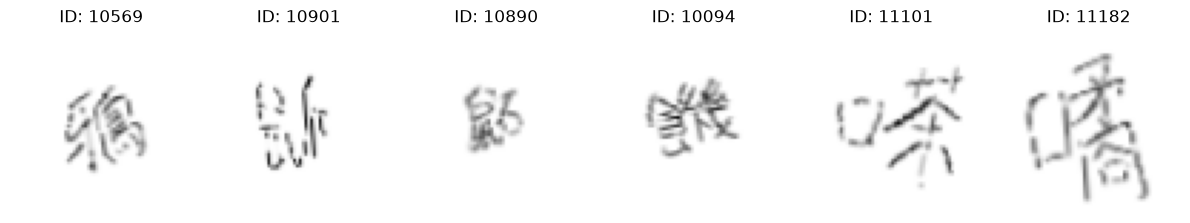

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

keras.utils.set_random_seed(42)

IMG = 64
BATCH = 32
BACKGROUND = 1.0
SAMPLES_PER_CLASS = 200

augment = keras.Sequential([
    layers.RandomRotation(
        0.035, fill_mode="constant", fill_value=BACKGROUND
    ),
    layers.RandomZoom(
        0.10, fill_mode="constant", fill_value=BACKGROUND
    ),
    layers.RandomTranslation(
        0.05, 0.05, fill_mode="constant", fill_value=BACKGROUND
    ),
])

def read_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=1)
    image = tf.image.resize(image, [IMG, IMG]) / 255.0
    return image, label

def make_dataset(rows, training=False):
    paths, labels = zip(*rows)
    paths = tf.constant(paths)
    label_tensor = tf.constant(labels, dtype=tf.int32)

    if training:
        counts = Counter(labels)
        seen = defaultdict(int)
        repeats = []

        for label in labels:
            base, extra = divmod(SAMPLES_PER_CLASS, counts[label])
            repeats.append(base + int(seen[label] < extra))
            seen[label] += 1

        ds = tf.data.Dataset.from_tensor_slices(
            (paths, label_tensor, tf.constant(repeats, dtype=tf.int64))
        )
        # 先打亂原圖，再展開每張圖嘅增強次數
        ds = ds.shuffle(
            min(len(rows), 50_000), seed=42, reshuffle_each_iteration=True
        )
        ds = ds.flat_map(
            lambda path, label, repeat: (
                tf.data.Dataset.from_tensors((path, label)).repeat(repeat)
            )
        )
        ds = ds.shuffle(
            min(sum(repeats), 20_000), seed=43, reshuffle_each_iteration=True
        )
        ds = ds.apply(tf.data.experimental.assert_cardinality(sum(repeats)))
    else:
        ds = tf.data.Dataset.from_tensor_slices((paths, label_tensor))

    ds = ds.map(read_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)

    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y))

    return ds.prefetch(1)

train_ds = make_dataset(train_rows, training=True)
test_ds = make_dataset(test_rows)

TOTAL_TRAIN_SAMPLES = N * SAMPLES_PER_CLASS

print("每個字每輪嘅訓練樣本數：", SAMPLES_PER_CLASS)
print("今次每輪嘅訓練樣本總數：", TOTAL_TRAIN_SAMPLES)
print("今次每輪批數：", int(train_ds.cardinality().numpy()))
print("測試圖片數：", len(test_rows))

images, labels = next(iter(train_ds))
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))

for ax, image, label in zip(axes, images[:6], labels[:6]):
    ax.imshow(image[:, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"ID: {classes[int(label)]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model(name):
    inputs = keras.Input(shape=(IMG, IMG, 1))
    x = inputs

    if name == "A_simple":
        # 淺層基線：兩層卷積，每層之後做池化
        for filters in (24, 48):
            x = layers.Conv2D(
                filters, 3, padding="same", activation="relu"
            )(x)
            x = layers.MaxPooling2D()(x)

    elif name == "B_deep":
        # 深層模型：每個區塊有兩層卷積，再做池化
        for filters in (24, 48, 96):
            for _ in range(2):
                x = layers.Conv2D(
                    filters, 3, padding="same", use_bias=False
                )(x)
                x = layers.BatchNormalization()(x)
                x = layers.ReLU()(x)
            x = layers.MaxPooling2D()(x)

    elif name == "C_residual":
        # 殘差模型：將捷徑分支同卷積分支相加
        for filters in (24, 48, 96):
            skip = layers.Conv2D(
                filters, 1, strides=2, padding="same"
            )(x)
            x = layers.Conv2D(
                filters, 3, strides=2, padding="same", activation="relu"
            )(x)
            x = layers.Conv2D(filters, 3, padding="same")(x)
            x = layers.Add()([x, skip])
            x = layers.ReLU()(x)

    else:
        raise ValueError(f"未知模型：{name}")

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(N, activation="softmax")(x)

    return keras.Model(inputs, outputs, name=name)

NAMES = ["A_simple", "B_deep", "C_residual"]

print("今次類別數：", N)

for name in NAMES:
    model = build_model(name)
    print(
        f"{name}: 輸出形狀 = {model.output_shape}，"
        f"參數量 = {model.count_params():,}"
    )

今次類別數： 13065
A_simple: 輸出形狀 = (None, 13065)，參數量 = 1,702,313
B_deep: 輸出形狀 = (None, 13065)，參數量 = 1,860,065
C_residual: 輸出形狀 = (None, 13065)，參數量 = 1,865,009


In [10]:
from pathlib import Path
import json
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

assert QUICK_TEST and N == 20, "請保持 QUICK_TEST = True，再依次跑第四至第六格"
assert tf.config.list_physical_devices("GPU"), "Notebook 未偵測到 GPU"

# 先確認一個運算真係喺 GPU 執行，而唔係只見到裝置名稱
with tf.device("/GPU:0"):
    probe = tf.linalg.matmul(tf.ones((32, 32)), tf.ones((32, 32)))
    probe.numpy()

print("測試運算裝置：", probe.device)
assert "GPU:0" in probe.device, "測試運算冇喺 GPU 執行"

OUT = Path.home() / "DIT5411" / "results" / "local_quick"
OUT.mkdir(parents=True, exist_ok=True)

(OUT / "labels.json").write_text(
    json.dumps(classes, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

results = []

for name in NAMES:
    print(f"\n===== 本機試訓練：{name} =====")
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    model = build_model(name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    model.fit(
        train_ds,
        epochs=1,
        callbacks=[
            keras.callbacks.CSVLogger(str(OUT / f"{name}_history.csv"))
        ],
        verbose=1,
    )

    scores = model.evaluate(test_ds, return_dict=True, verbose=0)
    model.save(str(OUT / f"{name}.keras"))

    results.append({
        "model": name,
        "classes": N,
        "epochs": 1,
        "parameters": model.count_params(),
        "test_images": len(test_rows),
        "test_accuracy_pct": round(100 * scores["accuracy"], 2),
    })

    pd.DataFrame(results).to_csv(OUT / "results.csv", index=False)
    print(f"{name} 測試準確率：{100 * scores['accuracy']:.2f}%")

print("\n===== 本機 20 類試跑結果 =====")
display(
    pd.DataFrame(results)
    .sort_values("test_accuracy_pct", ascending=False)
    .reset_index(drop=True)
)
print("結果已儲存：", OUT / "results.csv")

測試運算裝置： /job:localhost/replica:0/task:0/device:GPU:0

===== 本機試訓練：A_simple =====


/home/orinchan/DIT5411/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795460686.814582    1568 service.cc:154] XLA service 0x1d05fab0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795460686.814614    1568 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Ti Laptop GPU, Compute Capability 8.6 (Driver: 13.3.0[610.62.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795460686.857600    1568 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795460687.311505    1568 cuda_dnn.cc:442] Loaded cuDNN version 92801
I0000 00:00:1795460687.559418    2211 subproc

 27/125 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0405 - loss: 3.0033

I0000 00:00:1795460689.912718    1568 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.0448 - loss: 2.9993
A_simple 測試準確率：3.73%

===== 本機試訓練：B_deep =====


/home/orinchan/DIT5411/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.2470 - loss: 2.4808
B_deep 測試準確率：3.73%

===== 本機試訓練：C_residual =====


/home/orinchan/DIT5411/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.0390 - loss: 2.9982
C_residual 測試準確率：4.10%

===== 本機 20 類試跑結果 =====


,model,classes,epochs,parameters,test_images,test_accuracy_pct
0,C_residual,20,1,182204,268,4.10
1,A_simple,20,1,19508,268,3.73
2,B_deep,20,1,177260,268,3.73


結果已儲存： /home/orinchan/DIT5411/results/local_quick/results.csv


In [16]:
import time
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

assert not QUICK_TEST and N == 13065, "請先用全量設定跑第四至第六格"
assert tf.config.list_physical_devices("GPU"), "Notebook 未偵測到 GPU"
assert len(train_rows) + len(test_rows) == 684677, "原始圖片總數唔啱"
assert TOTAL_TRAIN_SAMPLES == N * SAMPLES_PER_CLASS

WARMUP_BATCHES = 20
TIMED_BATCHES = 100
PROBE_BATCHES = WARMUP_BATCHES + TIMED_BATCHES
FULL_BATCHES = int(train_ds.cardinality().numpy())

assert FULL_BATCHES == (TOTAL_TRAIN_SAMPLES + BATCH - 1) // BATCH
assert FULL_BATCHES >= PROBE_BATCHES

class BatchTimer(keras.callbacks.Callback):
    def on_train_batch_begin(self, batch, logs=None):
        if batch == WARMUP_BATCHES:
            self.started_at = time.perf_counter()

    def on_train_batch_end(self, batch, logs=None):
        if batch == PROBE_BATCHES - 1:
            self.elapsed = time.perf_counter() - self.started_at

print(f"正式類別數：{N:,}｜每批圖片：{BATCH}")
print(f"正式每輪批數：{FULL_BATCHES:,}")
print(f"每款短跑：{WARMUP_BATCHES} 批熱身 + {TIMED_BATCHES} 批計時")

speed_rows = []

for name in NAMES:
    print(f"\n===== 短跑測速：{name} =====")
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    model = build_model(name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )

    timer = BatchTimer()
    model.fit(
        train_ds.take(PROBE_BATCHES),
        epochs=1,
        shuffle=False,
        callbacks=[timer],
        verbose=1,
    )

    seconds_per_batch = timer.elapsed / TIMED_BATCHES
    speed_rows.append({
        "model": name,
        "batch_size": BATCH,
        "ms_per_batch": round(seconds_per_batch * 1000, 1),
        "estimated_hours_per_epoch": round(
            seconds_per_batch * FULL_BATCHES / 3600, 2
        ),
    })

    del model, timer

speed_table = pd.DataFrame(speed_rows)
print("\n===== 全量設定短跑測速（唔係正式成績） =====")
display(speed_table)

正式類別數：13,065｜每批圖片：32
正式每輪批數：81,657
每款短跑：20 批熱身 + 100 批計時

===== 短跑測速：A_simple =====
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.0018 - loss: 8.5186

===== 短跑測速：B_deep =====
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.0013 - loss: 8.4692

===== 短跑測速：C_residual =====
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 5.2083e-04 - loss: 8.4836

===== 全量設定短跑測速（唔係正式成績） =====


,model,batch_size,ms_per_batch,estimated_hours_per_epoch
0,A_simple,32,9.6,0.22
1,B_deep,32,30.6,0.69
2,C_residual,32,13.9,0.31


In [17]:
from pathlib import Path
import json
import time

import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

assert not QUICK_TEST and N == 13065
assert tf.config.list_physical_devices("GPU"), "Notebook 未偵測到 GPU"
assert len(train_rows) + len(test_rows) == 684677
assert len(split_exceptions) == 43
assert SAMPLES_PER_CLASS == 200
assert TOTAL_TRAIN_SAMPLES == N * SAMPLES_PER_CLASS

full_batches = int(train_ds.cardinality().numpy())
assert full_batches == (TOTAL_TRAIN_SAMPLES + BATCH - 1) // BATCH

EPOCHS = 1
OUT = Path.home() / "DIT5411" / "results" / f"full_e{EPOCHS}_b{BATCH}"
OUT.mkdir(parents=True, exist_ok=True)

csv_path = OUT / "results.csv"
config_path = OUT / "run_config.json"
config = {
    "classes": N,
    "epochs": EPOCHS,
    "batch_size": BATCH,
    "image_size": IMG,
    "samples_per_class_per_epoch": SAMPLES_PER_CLASS,
    "original_train_images": len(train_rows),
    "test_images": len(test_rows),
    "split_exception_count": len(split_exceptions),
}

if config_path.exists():
    saved_config = json.loads(config_path.read_text(encoding="utf-8"))
    assert saved_config == config, "設定同舊結果唔同，請換輸出資料夾"
else:
    config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

(OUT / "labels.json").write_text(
    json.dumps(classes, ensure_ascii=False, indent=2), encoding="utf-8"
)

pd.DataFrame(
    split_exceptions,
    columns=["class_id", "total_images", "train_images", "test_images"],
).to_csv(OUT / "split_exceptions.csv", index=False)

results = pd.read_csv(csv_path).to_dict("records") if csv_path.exists() else []
done = {row["model"] for row in results}

print(f"每款每輪：{full_batches:,} 批")
print(f"測試圖片：{len(test_rows):,} 張")
print("輸出資料夾：", OUT)

for name in NAMES:
    model_path = OUT / f"{name}.keras"
    history_path = OUT / f"{name}_history.csv"

    if name in done and model_path.is_file():
        print(f"跳過 {name}：已有模型同正式測試成績")
        continue

    print(f"\n===== 正式訓練：{name} =====")
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    if model_path.is_file() and EPOCHS == 1:
        # 已完成一輪並存檔，但可能未完成測試
        print("已有一輪 checkpoint，直接重新做測試")
        model = keras.models.load_model(str(model_path))
    else:
        model = build_model(name)
        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
            jit_compile=False,
        )

        started = time.perf_counter()
        model.fit(
            train_ds,
            epochs=EPOCHS,
            shuffle=False,
            callbacks=[
                keras.callbacks.CSVLogger(str(history_path)),
                keras.callbacks.ModelCheckpoint(str(model_path)),
            ],
            verbose=1,
        )
        print(f"實際訓練時間：{(time.perf_counter() - started) / 60:.1f} 分鐘")

    print(f"\n===== 正式測試：{name} =====")
    scores = model.evaluate(test_ds, return_dict=True, verbose=1)

    results = [row for row in results if row["model"] != name]
    results.append({
        "model": name,
        "classes": N,
        "epochs": EPOCHS,
        "batch_size": BATCH,
        "parameters": model.count_params(),
        "test_images": len(test_rows),
        "test_accuracy_pct": 100 * float(scores["accuracy"]),
    })

    temp_csv = csv_path.with_suffix(".tmp")
    pd.DataFrame(results).to_csv(temp_csv, index=False)
    temp_csv.replace(csv_path)
    print(f"{name} 正式測試準確率：{100 * scores['accuracy']:.4f}%")

    del model

table = pd.DataFrame(results).sort_values(
    "test_accuracy_pct", ascending=False
).reset_index(drop=True)

print("\n===== 正式全量基線結果 =====")
display(table.round({"test_accuracy_pct": 4}))
print("成績已儲存：", csv_path)
print("分組例外已儲存：", OUT / "split_exceptions.csv")

每款每輪：81,657 批
測試圖片：162,817 張
輸出資料夾： /home/orinchan/DIT5411/results/full_e1_b32

===== 正式訓練：A_simple =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 996s 12ms/step - accuracy: 4.7302e-04 - loss: 10.0507
實際訓練時間：16.6 分鐘

===== 正式測試：A_simple =====
5089/5089 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 1.1670e-04 - loss: 13.0147
A_simple 正式測試準確率：0.0117%

===== 正式訓練：B_deep =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 2786s 34ms/step - accuracy: 0.1663 - loss: 5.6492
實際訓練時間：46.4 分鐘

===== 正式測試：B_deep =====
5089/5089 ━━━━━━━━━━━━━━━━━━━━ 49s 10ms/step - accuracy: 2.2111e-04 - loss: 93.1240
B_deep 正式測試準確率：0.0221%

===== 正式訓練：C_residual =====
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 1454s 18ms/step - accuracy: 3.9495e-04 - loss: 10.0162
實際訓練時間：24.2 分鐘

===== 正式測試：C_residual =====
5089/5089 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 6.1419e-05 - loss: 15.8159
C_residual 正式測試準確率：0.0061%

===== 正式全量基線結果 =====


,model,classes,epochs,batch_size,parameters,test_images,test_accuracy_pct
0,B_deep,13065,1,32,1860065,162817,0.0221
1,A_simple,13065,1,32,1702313,162817,0.0117
2,C_residual,13065,1,32,1865009,162817,0.0061


成績已儲存： /home/orinchan/DIT5411/results/full_e1_b32/results.csv
分組例外已儲存： /home/orinchan/DIT5411/results/full_e1_b32/split_exceptions.csv


In [18]:
from pathlib import Path
from collections import Counter
import numpy as np
import tensorflow as tf
from tensorflow import keras

OUT = Path.home() / "DIT5411" / "results" / "full_e1_b32"
model_path = OUT / "B_deep.keras"

assert model_path.is_file(), f"搵唔到模型：{model_path}"

keras.backend.clear_session()
check_model = keras.models.load_model(str(model_path), compile=False)

true_labels = []
pred_labels = []

for images, labels in test_ds.unbatch().batch(32).take(100):
    probabilities = check_model(images, training=False)
    predictions = tf.argmax(probabilities, axis=1).numpy()

    true_labels.extend(labels.numpy().tolist())
    pred_labels.extend(predictions.tolist())

true_labels = np.asarray(true_labels)
pred_labels = np.asarray(pred_labels)

print("抽查測試圖片數：", len(true_labels))
print("抽查真實類別數：", len(np.unique(true_labels)))
print("模型預測出嘅不同類別數：", len(np.unique(pred_labels)))
print("抽查準確率（唔係完整測試成績）：",
      f"{100 * np.mean(true_labels == pred_labels):.4f}%")

print("\n最常預測嘅 10 個類別：")
for label, count in Counter(pred_labels).most_common(10):
    print(f"類別 ID {classes[label]}：{count} 次")

del check_model

抽查測試圖片數： 3200
抽查真實類別數： 187
模型預測出嘅不同類別數： 11
抽查準確率（唔係完整測試成績）： 0.0000%

最常預測嘅 10 個類別：
類別 ID 9879：2813 次
類別 ID 9880：274 次
類別 ID 9803：64 次
類別 ID 9901：20 次
類別 ID 9729：12 次
類別 ID 9807：8 次
類別 ID 9804：4 次
類別 ID 9882：2 次
類別 ID 9513：1 次
類別 ID 958：1 次


In [52]:
import json
import pandas as pd
from tensorflow import keras
from IPython.display import display

assert N == 13065 and not QUICK_TEST
assert len(test_rows) == 162_817, f"測試圖數量唔啱：{len(test_rows)}"
assert {y for _, y in test_rows} == set(range(N)), "測試集類別唔齊"

test_csv = OUT_BN / "test_results.csv"
assert not test_csv.exists(), "已經做過正式測試，唔好重複測試"

final_test_ds = make_dataset(test_rows, training=False)

test_table = []
for name in NAMES_BN:
    keras.backend.clear_session()
    state = json.loads((OUT_BN / f"{name}_state.json").read_text())
    model = keras.models.load_model(str(OUT_BN / f"{name}_best.keras"))

    print(f"\n===== 正式測試：{name}（第 {state['best_epoch']} 輪）=====")
    scores = model.evaluate(final_test_ds, return_dict=True, verbose=1)

    test_table.append({
        "model": name,
        "parameters": model.count_params(),
        "epochs_trained": state["epochs_done"],
        "best_epoch": state["best_epoch"],
        "val_acc_pct": round(100 * state["best_val_acc"], 2),
        "test_acc_pct": round(100 * float(scores["accuracy"]), 2),
        "test_loss": round(float(scores["loss"]), 4),
        "test_images": len(test_rows),
    })
    del model

result = pd.DataFrame(test_table).sort_values(
    "test_acc_pct", ascending=False
).reset_index(drop=True)
result.to_csv(test_csv, index=False)

print("\n===== 正式測試結果（13,065 類）=====")
display(result)
print("已儲存：", test_csv)


===== 正式測試：A_spatial（第 2 輪）=====
5089/5089 ━━━━━━━━━━━━━━━━━━━━ 29s 6ms/step - accuracy: 0.8081 - loss: 0.8505

===== 正式測試：B_deeper（第 2 輪）=====
5089/5089 ━━━━━━━━━━━━━━━━━━━━ 32s 6ms/step - accuracy: 0.8886 - loss: 0.4896

===== 正式測試：C_residual（第 2 輪）=====
5089/5089 ━━━━━━━━━━━━━━━━━━━━ 39s 8ms/step - accuracy: 0.9092 - loss: 0.3859

===== 正式測試結果（13,065 類）=====


,model,parameters,epochs_trained,best_epoch,val_acc_pct,test_acc_pct,test_loss,test_images
0,C_residual,5484249,2,2,92.09,90.92,0.3859,162817
1,B_deeper,5472537,2,2,90.33,88.86,0.4896,162817
2,A_spatial,5460825,2,2,83.59,80.81,0.8505,162817


已儲存： /home/orinchan/DIT5411/results/full_bn_e2_b32/test_results.csv
